# ADY201m — AI, DATA SCIENCE WITH PYTHON & SQL
## REPORT 2 — ONGOING ASSESSMENT 2
**Nội dung:** EDA, chuẩn bị đặc trưng, xây dựng và đánh giá mô hình.

**Đề tài:** Phân loại nhãn tiền tiểu đường/tiểu đường ở người tham gia BRFSS2015 từ 30–59 tuổi.
**Lớp:** AI2104 · **Nhóm:** 6 · **Ngày chạy lại:** 22/10/2026.

| Thành viên | Mã sinh viên |Phần trăm đóng góp|
|---|---|---|
| Trần Tuấn Hiệp | HE211144 |40%|
| Nguyễn Thế Hải | HE211655 |30%|
| Trần Công Du | HE211007 |30%|

**Phạm vi:** Người tham gia 30–59 tuổi, bất kể việc làm. Loại hồ sơ chỉ tiểu đường khi mang thai trước gộp nhãn: lớp 0 = DIABETE3=3; lớp 1 = DIABETE3=1/4. Mục đích học thuật, không dự đoán phát bệnh tương lai.

**Đầu vào:** Bản chính từ ongoing 1 có 116.662 dòng × 22 cột (21 feature + nhãn), giữ duplicate. Bản đối chiếu không duplicate có 102.826 dòng. Không làm sạch hay đổi nhãn lần nữa.

**Thiết kế Phần 3:** 3 bộ 18/16/21 feature × 2 bản giữ/loại duplicate × 4 mô hình = **24 cấu hình có trọng số**. Nhóm dùng Logistic Regression làm mô hình tham chiếu đơn giản và ba mô hình cây để đối chiếu. Nhóm giữ tham số cố định, không tuning, CV/OOF hoặc tìm ngưỡng trong Ongoing 2. Vì nhóm chỉ chạy cấu hình có trọng số, báo cáo này chưa đo mức cải thiện so với mô hình chưa trọng số.

**Trạng thái thực thi:** xem ngày chạy, phiên bản thư viện và phạm vi thực thi tại `metadata.execution_provenance` của notebook và `run_info.json` đi kèm. Nhóm lưu output cho EDA, preprocessing, đánh giá 24 mô hình và phụ lục.


## GRADING RUBRIC

*(This section is reserved for the instructor to grade and evaluate student work)*

| Criteria | Assessment Content | Max Score | Score Achieved | Lecturer's Feedback |
| :--- | :--- | :---: | :---: | :--- |
| **1. Exploratory Data Analysis (EDA)** | Univariate, bivariate & multivariate analysis, visualization, and meaningful business insights. | **3.0 pts** | | |
| **2. Feature Engineering & Preparation** | Proper categorical encoding, feature scaling, feature selection/creation, and train-test split. | **3.0 pts** | | |
| **3. Model Building & Evaluation** | Implementation of baseline & advanced models, performance metric evaluation, and model comparison. | **3.0 pts** | | |
| **4. Discussion & Conclusion** | Clear business interpretation of results, actionable recommendations, and next steps. | **1.0 pt** | | |
| **TOTAL SCORE** | **Overall evaluation of Report 2 execution** | **10.0 pts** | | |

---

### Chuẩn bị chạy notebook

Đặt notebook cạnh thư mục `data/` gồm hai CSV và metadata đi kèm. Cần pandas, numpy, scipy, matplotlib, seaborn, scikit-learn, xgboost, joblib, threadpoolctl và IPython; phiên bản của lần chạy nằm trong `requirements.txt`.

Chạy từ trên xuống. Tạo hoặc kiểm tra manifest theo hash dữ liệu, cố định seed 42; EDA chỉ dùng Train. Phần 3 chỉ dùng train/test từ manifest, không sử dụng các fold CV đã lưu để huấn luyện mô hình. Test được giữ riêng trong lần chạy này, nhưng vẫn là holdout nội bộ từ cùng nguồn CDC2015, không phải bộ xác nhận ngoài. Tỷ lệ mô tả mẫu, chưa dùng trọng số khảo sát.


**Phân công công cụ:** SQLite thực hiện lọc, đếm, gom nhóm, tạo bản loại trùng, lập bảng và xếp hạng. pandas chỉ đọc kết quả truy vấn để hiển thị hoặc truyền sang thư viện tính toán/vẽ. NumPy/scipy/scikit-learn thực hiện tương quan, VIF, kiểm định, preprocessing và huấn luyện. Nhóm giữ nguồn và tạo view loại trùng bằng MIN(row_id) trên đủ 22 cột.

**Quy ước màu:** so sánh hai nhóm dùng cam cho nhóm 0 và tím cho nhóm 1. Các biểu đồ một chuỗi thống kê, gồm VIF/ANOVA/Chi-square, dùng xanh nước biển. Heatmap tỷ lệ dùng dải cam–đỏ; heatmap tương quan dùng cam–trắng–đỏ cho hệ số âm–0–dương.


In [1]:
from pathlib import Path
import json, hashlib, csv, sqlite3, math
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

BASE = Path.cwd()
DATA = BASE / "data"
assert DATA.is_dir(), "Đặt thư mục data cạnh notebook và chạy từ thư mục chứa notebook."
TABLES, FIGS, MODELS = BASE / "tables", BASE / "figures", BASE / "models"
for folder in [TABLES, FIGS, MODELS]:
    folder.mkdir(exist_ok=True)
SEED = 42
TARGET = "Diabetes_binary"
FEATURES = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "BMI",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Sex",
    "Age",
    "Education",
    "Income",
]
NUMERIC_FEATURES = ["BMI", "MentHlth", "PhysHlth"]
ORDINAL_DOMAINS = {
    "Age": list(range(3, 9)),
    "Education": list(range(1, 7)),
    "Income": list(range(1, 9)),
    "GenHlth": list(range(1, 6)),
}
BINARY = [c for c in FEATURES if c not in NUMERIC_FEATURES and c not in ORDINAL_DOMAINS]
DROP_FEATURES_16 = ["Fruits", "Veggies", "Sex", "CholCheck", "AnyHealthcare"]
DROP_FEATURES_18 = ["Stroke", "Sex", "PhysHlth"]
FEATURE_SETS = {
    "full_21": FEATURES.copy(),
    "reduced_16": [feature for feature in FEATURES if feature not in DROP_FEATURES_16],
    "reduced_18": [feature for feature in FEATURES if feature not in DROP_FEATURES_18],
}
FEATURE_SET_ORDER = ["reduced_18", "reduced_16", "full_21"]
meta = json.loads((DATA / "dataset_metadata.json").read_text(encoding="utf-8"))
assert meta["target_mapping"] == {"1": 1, "3": 0, "4": 1}
assert meta["population"]["allowed_age_codes"] == list(range(3, 9))
assert 2 in meta["excluded_target_codes"]
actual_sha256 = hashlib.sha256(
    (DATA / "cleaned_cdc2015_keep_duplicates.csv").read_bytes()
).hexdigest()
if "clean_sha256" in meta:
    assert actual_sha256 == meta["clean_sha256"], "SHA-256 không khớp metadata."
else:
    print(
        "Metadata chưa có SHA-256 tham chiếu; ghi nhận hash hiện tại, tiếp tục kiểm tra cấu trúc và dữ liệu."
    )
meta["clean_sha256"] = actual_sha256


# SQLite owns data selection, aggregation and result tables. DataFrames only
# carry query results to scikit-learn, statistical routines and plotting.
if "DB" in globals():
    DB.close()
DB = sqlite3.connect(":memory:")
DB.row_factory = sqlite3.Row
DB.create_function(
    "sqrt", 1, lambda value: math.sqrt(max(0.0, value)) if value is not None else None
)


def ident(name):
    return '"' + name.replace('"', '""') + '"'


def records(sql, params=()):
    return [dict(row) for row in DB.execute(sql, params)]


def scalar(sql, params=()):
    return DB.execute(sql, params).fetchone()[0]


def table(sql, params=(), dtype=None):
    return pd.read_sql_query(sql, DB, params=params, dtype=dtype)


def export_sql(sql, path, params=()):
    cursor = DB.execute(sql, params)
    with Path(path).open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.writer(stream)
        writer.writerow([column[0] for column in cursor.description])
        writer.writerows(cursor)


def save_table(sql, name, params=()):
    export_sql(sql, TABLES / (name + ".csv"), params)


def load_data_csv(path, name):
    columns = [TARGET] + FEATURES
    with Path(path).open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.reader(stream)
        assert next(reader) == columns
        DB.execute(
            f"CREATE TABLE {ident(name)} (row_id INTEGER PRIMARY KEY, "
            + ", ".join(f"{ident(c)} NUMERIC NOT NULL" for c in columns)
            + ")"
        )
        DB.executemany(
            f"INSERT INTO {ident(name)} VALUES ("
            + ",".join("?" for _ in range(23))
            + ")",
            ((i, *row) for i, row in enumerate(reader)),
        )
    invalid = " OR ".join(
        f"typeof({ident(c)}) NOT IN ('integer','real') OR {ident(c)} != CAST({ident(c)} AS INTEGER) "
        f"OR {ident(c)} < -32768 OR {ident(c)} > 32767"
        for c in columns
    )
    assert scalar(f"SELECT COUNT(*) FROM {ident(name)} WHERE {invalid}") == 0


ALL_COLUMNS = ", ".join(ident(c) for c in [TARGET] + FEATURES)
FEATURE_COLUMNS = ", ".join(ident(c) for c in FEATURES)
load_data_csv(DATA / "cleaned_cdc2015_keep_duplicates.csv", "clean_data")
load_data_csv(DATA / "cleaned_cdc2015_no_duplicates.csv", "reference_dedup")
# Keep the first row of each full 22-column profile without removing source rows.
DB.execute(
    f"CREATE TABLE dedup_ids AS SELECT MIN(row_id) AS row_id FROM clean_data GROUP BY {ALL_COLUMNS}"
)
DB.execute("CREATE UNIQUE INDEX dedup_row_id ON dedup_ids(row_id)")
DB.execute(
    "CREATE VIEW clean_dedup AS SELECT * FROM clean_data WHERE row_id IN (SELECT row_id FROM dedup_ids)"
)
assert scalar("SELECT COUNT(*) FROM clean_data") == 116662
assert scalar("SELECT COUNT(*) FROM clean_dedup") == 102826
assert (
    scalar("SELECT COUNT(*) FROM clean_data")
    - scalar("SELECT COUNT(*) FROM clean_dedup")
    == 13836
)
assert records(
    "SELECT Diabetes_binary, COUNT(*) AS n FROM clean_data GROUP BY Diabetes_binary ORDER BY Diabetes_binary"
) == [{"Diabetes_binary": 0, "n": 103921}, {"Diabetes_binary": 1, "n": 12741}]
assert (
    scalar(
        f"SELECT COUNT(*) FROM (SELECT {ALL_COLUMNS} FROM clean_dedup EXCEPT SELECT {ALL_COLUMNS} FROM reference_dedup)"
    )
    == 0
)
assert scalar("SELECT COUNT(*) FROM reference_dedup") == scalar(
    f"SELECT COUNT(*) FROM (SELECT DISTINCT {ALL_COLUMNS} FROM reference_dedup)"
)
for column in [TARGET] + BINARY:
    assert (
        scalar(f"SELECT COUNT(*) FROM clean_data WHERE {ident(column)} NOT IN (0,1)")
        == 0
    )
for column, domain in ORDINAL_DOMAINS.items():
    assert (
        scalar(
            f"SELECT COUNT(*) FROM clean_data WHERE {ident(column)} NOT IN ({','.join('?' for _ in domain)})",
            domain,
        )
        == 0
    )
for column in ["MentHlth", "PhysHlth"]:
    assert (
        scalar(
            f"SELECT COUNT(*) FROM clean_data WHERE {ident(column)} NOT BETWEEN 0 AND 30"
        )
        == 0
    )
assert scalar("SELECT COUNT(*) FROM clean_data WHERE BMI <= 0") == 0

DB.execute(
    "CREATE TABLE feature_catalog (position INTEGER PRIMARY KEY, Feature TEXT UNIQUE)"
)
DB.executemany("INSERT INTO feature_catalog VALUES (?, ?)", enumerate(FEATURES))
DB.execute(
    "CREATE TABLE feature_sets (name TEXT, Feature TEXT, PRIMARY KEY (name, Feature))"
)
DB.executemany(
    "INSERT INTO feature_sets VALUES (?, ?)",
    ((name, column) for name, cols in FEATURE_SETS.items() for column in cols),
)
display(table("""
    SELECT Diabetes_binary, COUNT(*) AS "Số dòng",
           100.0 * COUNT(*) / (SELECT COUNT(*) FROM clean_data) AS "Tỷ lệ (%)"
    FROM clean_data GROUP BY Diabetes_binary ORDER BY Diabetes_binary
"""))
print(
    "Dữ liệu chính:",
    scalar("SELECT COUNT(*) FROM clean_data"),
    "| Loại trùng:",
    scalar("SELECT COUNT(*) FROM clean_dedup"),
)

ORANGE, PURPLE, BLUE = "#E67E22", "#7E3FB2", "#1674B8"
PALETTE = {0: ORANGE, 1: PURPLE}
DISCRETE_COLOR = CONTINUOUS_COLOR = BLUE
CORRELATION_CMAP = LinearSegmentedColormap.from_list(
    "orange_white_red", [ORANGE, "#FFFFFF", "#C62828"]
)
sns.set_theme(style="whitegrid", font="DejaVu Sans", palette=[ORANGE, PURPLE])
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.facecolor": "white",
    }
)


def save_and_show_figure(name, fig=None):
    fig = fig or plt.gcf()
    fig.savefig(FIGS / (name + ".png"), dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def note(text):
    display(Markdown(text))


,Diabetes_binary,Số dòng,Tỷ lệ (%)
0,0,103921,89.078706
1,1,12741,10.921294


Dữ liệu chính: 116662 | Loại trùng: 102826


In [2]:
# Group identifiers follow first occurrence, matching the existing manifest.
DB.execute(f"""
    CREATE TABLE profile_groups AS
    SELECT ROW_NUMBER() OVER (ORDER BY MIN(row_id)) - 1 AS group_id,
           {FEATURE_COLUMNS}
    FROM clean_data GROUP BY {FEATURE_COLUMNS}
""")
DB.execute(f"CREATE UNIQUE INDEX profile_key ON profile_groups ({FEATURE_COLUMNS})")
DB.execute(f"""
    CREATE TABLE row_groups AS
    SELECT d.row_id, g.group_id
    FROM clean_data AS d JOIN profile_groups AS g USING ({FEATURE_COLUMNS})
""")
DB.execute("CREATE UNIQUE INDEX row_group_id ON row_groups(row_id)")
DB.execute(
    "CREATE TABLE split_manifest (row_id INTEGER PRIMARY KEY, group_id INTEGER, split TEXT, cv_fold INTEGER)"
)
manifest_path, split_meta_path = (
    BASE / "split_manifest.csv",
    BASE / "split_metadata.json",
)
if manifest_path.is_file():
    saved = json.loads(split_meta_path.read_text(encoding="utf-8"))
    assert saved["data_sha256"] == actual_sha256
    with manifest_path.open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        DB.executemany(
            "INSERT INTO split_manifest VALUES (?, ?, ?, ?)",
            (
                (int(r["row_id"]), int(r["group_id"]), r["split"], int(r["cv_fold"]))
                for r in reader
            ),
        )
else:
    split_X = table(
        f"SELECT {FEATURE_COLUMNS} FROM clean_data ORDER BY row_id", dtype="int16"
    )
    split_y = np.array(
        [
            r["Diabetes_binary"]
            for r in records("SELECT Diabetes_binary FROM clean_data ORDER BY row_id")
        ]
    )
    split_groups = np.array(
        [
            r["group_id"]
            for r in records("SELECT group_id FROM row_groups ORDER BY row_id")
        ]
    )
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    train_index, test_index = next(outer.split(split_X, split_y, split_groups))
    DB.executemany(
        "INSERT INTO split_manifest VALUES (?, ?, 'test', -1)",
        enumerate(map(int, split_groups)),
    )
    DB.executemany(
        "UPDATE split_manifest SET split='train' WHERE row_id=?",
        ((int(i),) for i in train_index),
    )
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
    for fold, (_, val) in enumerate(
        inner.split(
            split_X.to_numpy()[train_index],
            split_y[train_index],
            split_groups[train_index],
        )
    ):
        DB.executemany(
            "UPDATE split_manifest SET cv_fold=? WHERE row_id=?",
            ((fold, int(train_index[j])) for j in val),
        )
    export_sql("SELECT * FROM split_manifest ORDER BY row_id", manifest_path)
    split_meta_path.write_text(
        json.dumps(
            {
                "data_sha256": actual_sha256,
                "seed": SEED,
                "method": "StratifiedGroupKFold outer first fold; inner 5 folds",
                "group_key": FEATURES,
                "label_in_group_key": False,
            },
            indent=2,
        ),
        encoding="utf-8",
    )
assert scalar("SELECT COUNT(*) FROM split_manifest") == 116662
assert (
    scalar(
        "SELECT COUNT(*) FROM split_manifest AS s LEFT JOIN row_groups AS g USING(row_id) WHERE g.row_id IS NULL OR s.group_id != g.group_id"
    )
    == 0
)
assert (
    scalar(
        "SELECT COUNT(*) FROM split_manifest WHERE split NOT IN ('train','test') OR split IS NULL OR cv_fold IS NULL OR (split='test' AND cv_fold != -1) OR (split='train' AND cv_fold NOT BETWEEN 0 AND 4)"
    )
    == 0
)
assert (
    scalar(
        "SELECT COUNT(*) FROM (SELECT group_id FROM split_manifest GROUP BY group_id HAVING COUNT(DISTINCT split)>1)"
    )
    == 0
)
assert (
    scalar(
        "SELECT COUNT(*) FROM (SELECT group_id FROM split_manifest WHERE split='train' GROUP BY group_id HAVING COUNT(DISTINCT cv_fold)>1)"
    )
    == 0
)
assert (
    scalar("SELECT COUNT(DISTINCT cv_fold) FROM split_manifest WHERE split='train'")
    == 5
)
assert (
    scalar(
        "SELECT COUNT(*) FROM (SELECT cv_fold FROM split_manifest JOIN clean_data USING(row_id) WHERE split='train' GROUP BY cv_fold HAVING COUNT(DISTINCT Diabetes_binary)!=2)"
    )
    == 0
)
DB.execute(
    f"CREATE VIEW train_data AS SELECT d.* FROM clean_data d JOIN split_manifest s USING(row_id) WHERE s.split='train'"
)
DB.execute(
    "CREATE VIEW dataset_rows AS SELECT 'keep_duplicates' AS Dataset, s.* FROM split_manifest s UNION ALL SELECT 'no_duplicates', s.* FROM split_manifest s JOIN clean_dedup d USING(row_id)"
)
DB.execute("""
    CREATE VIEW split_summary AS
    SELECT CASE split WHEN 'train' THEN 'Train' ELSE 'Test' END AS "Tập",
           COUNT(*) AS "Số dòng", SUM(Diabetes_binary=0) AS "Lớp 0",
           SUM(Diabetes_binary=1) AS "Lớp 1", 100.0*AVG(Diabetes_binary) AS "Lớp 1 (%)"
    FROM split_manifest JOIN clean_data USING(row_id) GROUP BY split
""")
display(table('SELECT * FROM split_summary ORDER BY "Tập" DESC'))
save_table('SELECT * FROM split_summary ORDER BY "Tập" DESC', "split_summary")
df_eda = table(f"SELECT {ALL_COLUMNS} FROM train_data ORDER BY row_id", dtype="int16")
X_train = table(
    f"SELECT {FEATURE_COLUMNS} FROM train_data ORDER BY row_id", dtype="int16"
)
y_train = np.array(
    [
        r[TARGET]
        for r in records("SELECT Diabetes_binary FROM train_data ORDER BY row_id")
    ],
    dtype=np.int16,
)
print("Đã kiểm tra manifest và không giao nhóm giữa Train/Test hoặc các fold.")


,Tập,Số dòng,Lớp 0,Lớp 1,Lớp 1 (%)
0,Train,93329,83137,10192,10.920507
1,Test,23333,20784,2549,10.924442


Đã kiểm tra manifest và không giao nhóm giữa Train/Test hoặc các fold.


# PART 1: EXPLORATORY DATA ANALYSIS (EDA) [3.0 POINTS]

Nhóm chỉ dùng **Train**, giữ phân bố và hồ sơ trùng hiện tại. Nhãn 0 = DIABETE3=3;
nhãn 1 = DIABETE3=1/4; mẫu gồm người 30–59 tuổi, đã loại DIABETE3=2 ở Ongoing 1.
Các tỷ lệ mô tả mẫu khảo sát tự khai, chưa dùng trọng số khảo sát và không chứng minh nhân quả.

**Cách đọc:** biểu đồ phân bố mô tả số hồ sơ; biểu đồ tỷ lệ nhóm mô tả % lớp 1 trong
từng mức đặc trưng. Histogram BMI theo lớp chuẩn hóa riêng từng lớp. Xem số mẫu và
bảng chi tiết tại Phụ lục A; nhóm ít hồ sơ có thể cho tỷ lệ kém ổn định.

Tham khảo cách dùng pandas/Seaborn trong
[Diabetes Prediction | EDA + Preprocessing + Models](https://www.kaggle.com/code/abdallahsaadelgendy/diabetes-prediction-eda-preprocessing-models)
(bản hiển thị Version 2 of 3). Nhóm giữ quy trình chia dữ liệu và preprocessing của dự án.


In [3]:
AGE_LABELS = ["30–34", "35–39", "40–44", "45–49", "50–54", "55–59"]
EDU_LABELS = [
    "Chưa học/\nmẫu giáo",
    "Lớp 1–8",
    "Lớp 9–11",
    "THPT",
    "CĐ/ĐH\n1–3 năm",
    "CĐ/ĐH\n≥4 năm",
]
INCOME_LABELS = [
    "<10k",
    "10–<15k",
    "15–<20k",
    "20–<25k",
    "25–<35k",
    "35–<50k",
    "50–<75k",
    "≥75k",
]
GEN_LABELS = ["Excellent", "Very good", "Good", "Fair", "Poor"]
LABEL_MAPS = {
    "Age": dict(enumerate(AGE_LABELS, 3)),
    "Education": dict(enumerate(EDU_LABELS, 1)),
    "Income": dict(enumerate(INCOME_LABELS, 1)),
    "GenHlth": dict(enumerate(GEN_LABELS, 1)),
}
EDA_LEVELS = {
    **{feature: [0, 1] for feature in BINARY},
    **ORDINAL_DOMAINS,
    "MentHlth": list(range(31)),
    "PhysHlth": list(range(31)),
}


DB.execute(
    "CREATE TABLE feature_levels (Feature TEXT, level INTEGER, position INTEGER, PRIMARY KEY(Feature,level))"
)
DB.executemany(
    "INSERT INTO feature_levels VALUES (?, ?, ?)",
    (
        (feature, level, position)
        for feature, levels in EDA_LEVELS.items()
        for position, level in enumerate(levels)
    ),
)
summary_parts = []
for feature in EDA_LEVELS:
    field = ident(feature)
    summary_parts.append(f"""
        SELECT l.Feature, l.level, l.position,
               COALESCE(g.sample_count,0) AS sample_count,
               COALESCE(g.positive_count,0) AS positive_count,
               g.positive_rate
        FROM feature_levels l LEFT JOIN (
            SELECT {field} AS level, COUNT(*) AS sample_count,
                   SUM(Diabetes_binary) AS positive_count,
                   100.0*AVG(Diabetes_binary) AS positive_rate
            FROM train_data GROUP BY {field}
        ) g ON g.level=l.level WHERE l.Feature='{feature}'
    """)
DB.execute("CREATE VIEW feature_summary AS " + " UNION ALL ".join(summary_parts))


def plot_rate_grid(features, label_maps, min_count=1):
    maximum = max(
        scalar(
            "SELECT MAX(positive_rate) FROM feature_summary WHERE Feature=? AND sample_count>=?",
            (feature, min_count),
        )
        or 0
        for feature in features
    )
    limit = min(100, max(10, np.ceil(maximum / 10) * 10 + 10))
    rows = (len(features) + 1) // 2
    fig, axes = plt.subplots(
        rows, 2, figsize=(14, 4 * rows), squeeze=False, sharey=True
    )
    for ax, feature in zip(axes.flat, features):
        values = records(
            "SELECT level, CASE WHEN sample_count>=? THEN positive_rate END AS rate FROM feature_summary WHERE Feature=? ORDER BY position",
            (min_count, feature),
        )
        positions = np.arange(len(values))
        ax.bar(
            positions,
            [r["rate"] if r["rate"] is not None else np.nan for r in values],
            color=BLUE,
        )
        labels = [
            label_maps.get(feature, {}).get(r["level"], str(r["level"])) for r in values
        ]
        step = 5 if len(labels) > 15 else 1
        ax.set(
            xticks=positions[::step],
            xticklabels=labels[::step],
            title=feature,
            ylabel="Lớp 1 trong nhóm (%)",
            ylim=(0, limit),
        )
        ax.tick_params(axis="x", labelrotation=20 if feature == "Income" else 0)
    for ax in list(axes.flat)[len(features) :]:
        ax.set_visible(False)
    fig.tight_layout()
    return fig


def plot_category_counts(features, label_maps, columns):
    rows = (len(features) + columns - 1) // columns
    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=((7 if columns == 2 else 4.5) * columns, 3.5 * rows),
        squeeze=False,
    )
    for ax, feature in zip(axes.flat, features):
        values = records(
            "SELECT level,sample_count FROM feature_summary WHERE Feature=? ORDER BY position",
            (feature,),
        )
        positions = np.arange(len(values))
        colors = [PALETTE[r["level"]] for r in values] if feature in BINARY else BLUE
        ax.bar(positions, [r["sample_count"] for r in values], color=colors)
        labels = [
            label_maps.get(feature, {}).get(r["level"], str(r["level"])) for r in values
        ]
        ax.set(
            title=feature,
            xlabel="",
            ylabel="Số hồ sơ",
            xticks=positions,
            xticklabels=labels,
        )
        if feature == "Income":
            ax.tick_params(axis="x", labelrotation=25)
    for ax in list(axes.flat)[len(features) :]:
        ax.set_visible(False)
    fig.tight_layout()
    return fig


def sql_quantile(column, probability, where="1=1", params=()):
    if column not in NUMERIC_FEATURES or not 0 <= probability <= 1:
        raise ValueError("Cột hoặc xác suất tứ phân vị không hợp lệ.")
    field = ident(column)
    count = scalar(f"SELECT COUNT({field}) FROM train_data WHERE {where}", params)
    if count == 0:
        return None
    position = (count - 1) * probability
    offset = int(position)
    return scalar(
        f"""
        SELECT MIN(value)+?*(MAX(value)-MIN(value)) FROM (
            SELECT {field} AS value FROM train_data
            WHERE {field} IS NOT NULL AND ({where})
            ORDER BY {field} LIMIT 2 OFFSET ?
        )
    """,
        (position - offset, *params, offset),
    )


## 1.1. Tổng quan và phân bố

### a. Chất lượng dữ liệu và phân bố nhãn

Bảng đầu kiểm tra đầu vào **sau Ongoing 1**, không thay thế báo cáo quá trình làm sạch dữ liệu nguồn.
Nhóm dùng SQLite để đếm dòng, đếm trùng, kiểm tra số thiếu, số giá trị khác nhau và MIN/MAX trên Train. Nhóm tính bảng biến số và tứ phân vị từ cùng bảng SQL, tính độ lệch chuẩn mẫu bằng tổng bình phương độ lệch trong SQL. Nhóm đếm nhãn bằng SQL và vẽ biểu đồ cột có số lượng và tỷ lệ.


**Cách đọc bảng:** “Kiểu đầu vào mô hình” được lấy từ dtype thực tế của DataFrame sạch trước preprocessing, không phải kiểu lưu trữ SQLite. Các phép chuẩn hóa và nội bộ mô hình có thể chuyển sang số thực. Số thiếu được kiểm tra trên Train đã làm sạch sau Ongoing 1; bảng nguồn có ràng buộc NOT NULL nên dữ liệu thiếu có thể bị chặn ngay khi nhập. Đây không phải quy trình kiểm tra missing của dữ liệu CDC gốc.


,Feature,Kiểu đầu vào mô hình,Số thiếu,Số giá trị khác nhau,Nhỏ nhất,Lớn nhất
0,Diabetes_binary,int16,0,2,0.0,1.0
1,HighBP,int16,0,2,0.0,1.0
2,HighChol,int16,0,2,0.0,1.0
3,CholCheck,int16,0,2,0.0,1.0
4,BMI,int16,0,79,12.0,98.0
5,Smoker,int16,0,2,0.0,1.0
6,Stroke,int16,0,2,0.0,1.0
7,HeartDiseaseorAttack,int16,0,2,0.0,1.0
8,PhysActivity,int16,0,2,0.0,1.0
9,Fruits,int16,0,2,0.0,1.0


Train: 93,329 dòng; trùng toàn bộ 22 cột: 11,071.


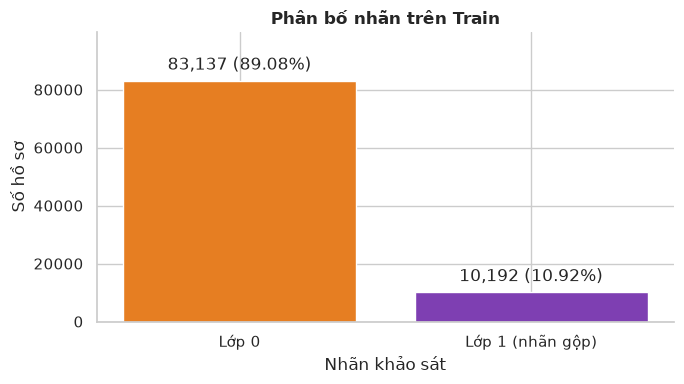

**Quan sát:** lớp 1 chiếm **10.92%** Train. Chỉ đoán lớp 0 đạt Accuracy **89.08%**, nhưng Recall lớp 1 bằng 0. Nhóm đọc Precision, Recall và F1 cùng Accuracy.

In [4]:
DB.execute(
    "CREATE TABLE data_summary (position INTEGER, Feature TEXT, dtype TEXT, missing_count INTEGER, distinct_count INTEGER, minimum REAL, maximum REAL)"
)
DB.execute(
    'CREATE TABLE numeric_summary (position INTEGER, Feature TEXT, count INTEGER, mean REAL, std REAL, min REAL, "25%" REAL, "50%" REAL, "75%" REAL, max REAL)'
)
for position, column in enumerate([TARGET] + FEATURES):
    field = ident(column)
    DB.execute(
        f"""
        INSERT INTO data_summary
        SELECT ?, ?, ?, COUNT(*)-COUNT({field}), COUNT(DISTINCT {field}), MIN({field}), MAX({field}) FROM train_data
    """,
        (position, column, str(df_eda[column].dtype)),
    )
    if column in NUMERIC_FEATURES:
        values = DB.execute(f"""
            SELECT COUNT({field}),AVG({field}),
                   CASE WHEN COUNT({field})>1 THEN sqrt(SUM(({field}-center)*({field}-center))/(COUNT({field})-1)) END,
                   MIN({field}), MAX({field})
            FROM train_data CROSS JOIN (SELECT AVG({field}) AS center FROM train_data)
        """).fetchone()
        DB.execute(
            "INSERT INTO numeric_summary VALUES (?,?,?,?,?,?,?,?,?,?)",
            (
                NUMERIC_FEATURES.index(column),
                column,
                values[0],
                values[1],
                values[2],
                values[3],
                sql_quantile(column, 0.25),
                sql_quantile(column, 0.5),
                sql_quantile(column, 0.75),
                values[4],
            ),
        )
DATA_SUMMARY_SQL = 'SELECT Feature, dtype AS "Kiểu đầu vào mô hình", missing_count AS "Số thiếu", distinct_count AS "Số giá trị khác nhau", minimum AS "Nhỏ nhất", maximum AS "Lớn nhất" FROM data_summary ORDER BY position'
NUMERIC_SUMMARY_SQL = 'SELECT Feature,count,mean,std,min,"25%","50%","75%",max FROM numeric_summary ORDER BY position'
display(table(DATA_SUMMARY_SQL))
save_table(DATA_SUMMARY_SQL, "ref_data_summary")
row_count = scalar("SELECT COUNT(*) FROM train_data")
duplicate_rows = scalar(
    f"SELECT COUNT(*)-(SELECT COUNT(*) FROM (SELECT DISTINCT {ALL_COLUMNS} FROM train_data)) FROM train_data"
)
print(f"Train: {row_count:,} dòng; trùng toàn bộ 22 cột: {duplicate_rows:,}.")
assert scalar("SELECT SUM(missing_count) FROM data_summary") == 0
DB.execute("""
    CREATE VIEW label_summary AS SELECT Diabetes_binary,COUNT(*) AS sample_count,
    100.0*COUNT(*)/(SELECT COUNT(*) FROM train_data) AS percent
    FROM train_data GROUP BY Diabetes_binary
""")
save_table("SELECT * FROM label_summary ORDER BY Diabetes_binary", "eda_target_counts")
values = records("SELECT * FROM label_summary ORDER BY Diabetes_binary")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    [r[TARGET] for r in values],
    [r["sample_count"] for r in values],
    color=[PALETTE[r[TARGET]] for r in values],
)
ax.set(
    title="Phân bố nhãn trên Train",
    xlabel="Nhãn khảo sát",
    ylabel="Số hồ sơ",
    xticks=[0, 1],
    xticklabels=["Lớp 0", "Lớp 1 (nhãn gộp)"],
    ylim=(0, 1.2 * scalar("SELECT MAX(sample_count) FROM label_summary")),
)
ax.bar_label(
    ax.containers[0],
    labels=[f"{r['sample_count']:,} ({r['percent']:.2f}%)" for r in values],
    padding=5,
)
fig.tight_layout()
save_and_show_figure("eda_01_target", fig)
positive_percent = scalar("SELECT percent FROM label_summary WHERE Diabetes_binary=1")
note(
    f"**Quan sát:** lớp 1 chiếm **{positive_percent:.2f}%** Train. Chỉ đoán lớp 0 đạt Accuracy **{100-positive_percent:.2f}%**, nhưng Recall lớp 1 bằng 0. Nhóm đọc Precision, Recall và F1 cùng Accuracy."
)


### b. Phân bố biến số và kiểm tra BMI

Nhóm dùng histogram cho BMI và hai biến số ngày; boxplot BMI giúp kiểm tra phần đuôi.
Nhóm giữ các điểm ngoài râu để kiểm tra, không tự xóa hồ sơ hay đổi nhãn.
Xem phân bố của 18 biến nhị phân/thứ bậc tại Phụ lục A.1.


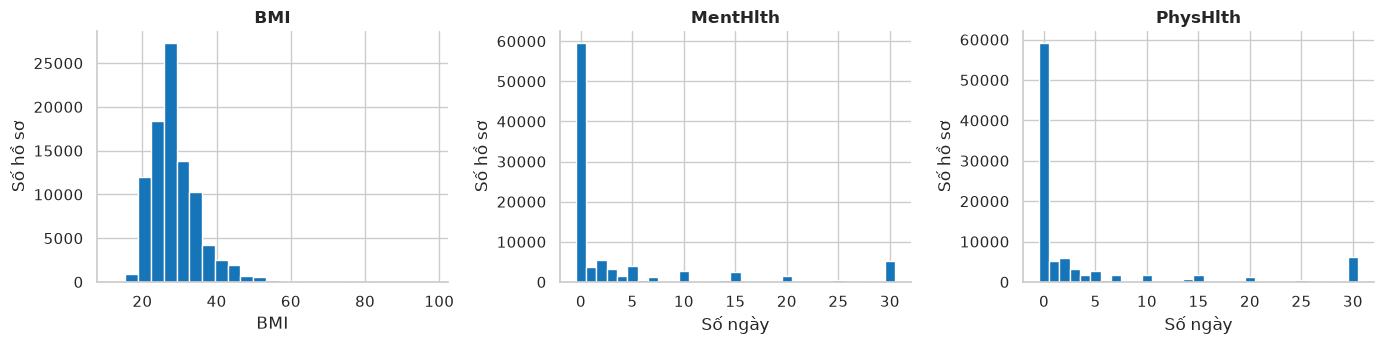

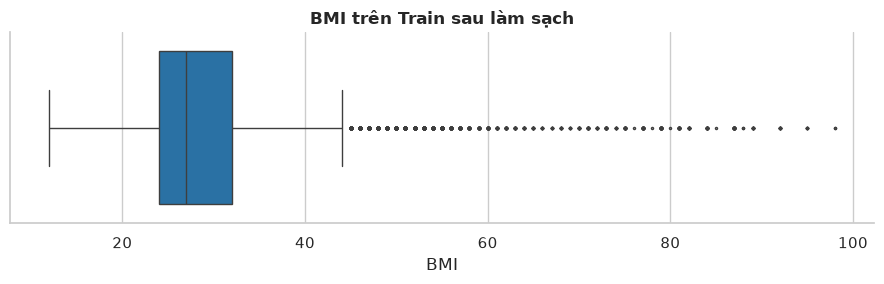

,Feature,count,mean,std,min,25%,50%,75%,max
0,BMI,93329,28.86,7.08,12.0,24.0,27.0,32.0,98.0
1,MentHlth,93329,3.80,7.98,0.0,0.0,0.0,3.0,30.0
2,PhysHlth,93329,3.86,8.28,0.0,0.0,0.0,2.0,30.0


**Quan sát:** BMI trung vị **27**, Q1–Q3 **24–32**. MentHlth/PhysHlth có **63.73%/63.32%** giá trị 0 ngày. StandardScaler đổi thang đo, không biến phân bố thành phân bố chuẩn.

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, feature in zip(axes, NUMERIC_FEATURES):
    bins = 25 if feature == "BMI" else np.arange(-0.5, 31.5)
    ax.hist(df_eda[feature], bins=bins, color=CONTINUOUS_COLOR, edgecolor="white")
    ax.set(
        title=feature,
        xlabel="BMI" if feature == "BMI" else "Số ngày",
        ylabel="Số hồ sơ",
    )
fig.tight_layout()
save_and_show_figure("eda_02_numeric_distributions", fig)

fig, ax = plt.subplots(figsize=(9, 3))
sns.boxplot(data=df_eda, x="BMI", color=CONTINUOUS_COLOR, fliersize=1.5, ax=ax)
ax.set(title="BMI trên Train sau làm sạch", xlabel="BMI")
fig.tight_layout()
save_and_show_figure("eda_03_bmi_boxplot", fig)

display(table(NUMERIC_SUMMARY_SQL).round(2))
save_table(NUMERIC_SUMMARY_SQL, "eda_numeric_summary")
bmi_summary = records(
    'SELECT "25%" AS q1,"50%" AS q2,"75%" AS q3 FROM numeric_summary WHERE Feature=?',
    ("BMI",),
)[0]
zero_rates = records(
    "SELECT 100.0*AVG(MentHlth=0) AS mental,100.0*AVG(PhysHlth=0) AS physical FROM train_data"
)[0]
note(
    f"**Quan sát:** BMI trung vị **{bmi_summary['q2']:.0f}**, Q1–Q3 **{bmi_summary['q1']:.0f}–{bmi_summary['q3']:.0f}**. MentHlth/PhysHlth có **{zero_rates['mental']:.2f}%/{zero_rates['physical']:.2f}%** giá trị 0 ngày. StandardScaler đổi thang đo, không biến phân bố thành phân bố chuẩn."
)


## 1.2. Đặc trưng và nhãn

### a. Biến nhị phân

Mỗi biến có hai thanh: tỷ lệ lớp 1 khi X=0 và X=1. Màu ở hình này biểu thị **giá trị X**.
Nhóm tính tỷ lệ trong từng mức; không dùng số lượng lớp 1 để so sánh các nhóm khác quy mô.


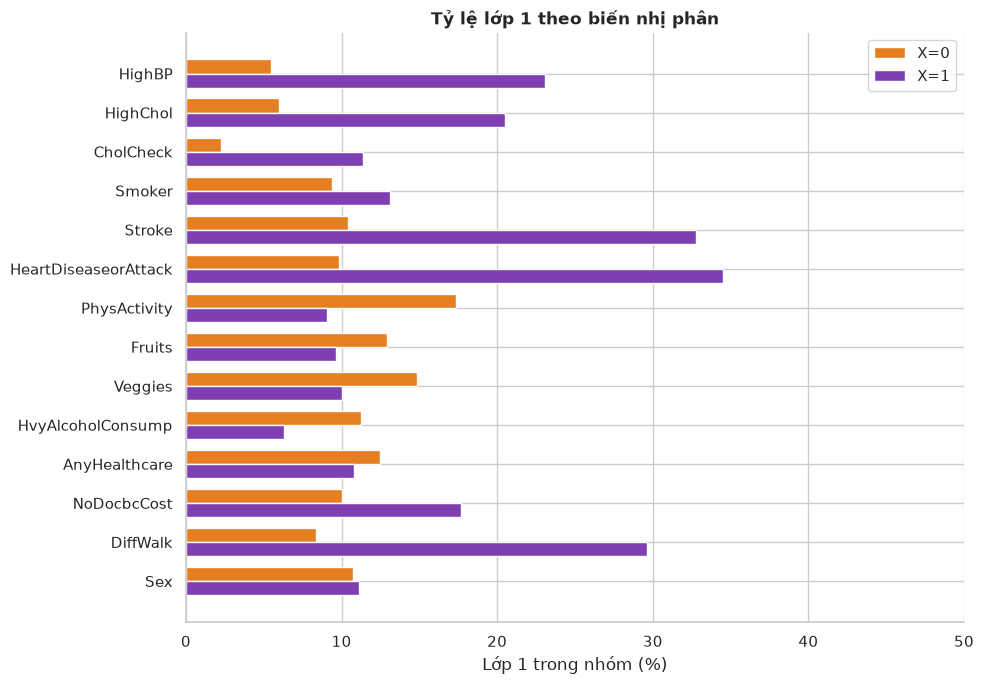

**Quan sát:** HeartDiseaseorAttack có chênh lệch lớn nhất: X=0 **9.86%**, X=1 **34.53%**. Đây là liên hệ chưa điều chỉnh các biến khác.

### Các chênh lệch cần đọc cùng số hồ sơ

**HeartDiseaseorAttack:** X=0: 9.86% (n=89,309); X=1: 34.53% (n=4,020).

**Stroke:** X=0: 10.42% (n=91,259); X=1: 32.80% (n=2,070).

**HvyAlcoholConsump:** X=0: 11.23% (n=87,526); X=1: 6.27% (n=5,803).

Nhóm quan sát tỷ lệ lớp 1 thấp hơn ở nhóm HvyAlcoholConsump=1. Chênh lệch chưa điều chỉnh tuổi, giới và các biến khác; nhóm không diễn giải thành tác dụng bảo vệ của rượu. Nhóm giữ Stroke trong bộ đầy đủ dù thử bỏ biến ở bộ 18.

In [6]:
DB.execute("""
    CREATE VIEW binary_rates AS
    SELECT f.position, f.Feature,
           MAX(CASE WHEN s.level=0 THEN positive_rate END) AS rate0,
           MAX(CASE WHEN s.level=1 THEN positive_rate END) AS rate1
    FROM feature_catalog f JOIN feature_summary s USING(Feature)
    WHERE f.Feature IN (SELECT Feature FROM feature_levels GROUP BY Feature HAVING COUNT(*)=2)
    GROUP BY f.position,f.Feature
""")
values = records("SELECT * FROM binary_rates ORDER BY position")
positions = np.arange(len(values))
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(
    positions - 0.18,
    [r["rate0"] for r in values],
    height=0.36,
    color=ORANGE,
    label="X=0",
)
ax.barh(
    positions + 0.18,
    [r["rate1"] for r in values],
    height=0.36,
    color=PURPLE,
    label="X=1",
)
maximum = scalar("SELECT MAX(MAX(rate0,rate1)) FROM binary_rates")
ax.set(
    yticks=positions,
    yticklabels=[r["Feature"] for r in values],
    title="Tỷ lệ lớp 1 theo biến nhị phân",
    xlabel="Lớp 1 trong nhóm (%)",
    xlim=(0, min(100, max(10, np.ceil(maximum / 10) * 10 + 10))),
)
ax.invert_yaxis()
ax.legend()
fig.tight_layout()
save_and_show_figure("eda_04_binary_rates", fig)
largest = records(
    "SELECT * FROM binary_rates WHERE rate0 IS NOT NULL AND rate1 IS NOT NULL ORDER BY ABS(rate1-rate0) DESC, position LIMIT 1"
)[0]
note(
    f"**Quan sát:** {largest['Feature']} có chênh lệch lớn nhất: X=0 **{largest['rate0']:.2f}%**, X=1 **{largest['rate1']:.2f}%**. Đây là liên hệ chưa điều chỉnh các biến khác."
)
display(Markdown("### Các chênh lệch cần đọc cùng số hồ sơ"))
for feature in ["HeartDiseaseorAttack", "Stroke", "HvyAlcoholConsump"]:
    values = records(
        "SELECT * FROM feature_summary WHERE Feature=? ORDER BY position", (feature,)
    )
    note(
        f"**{feature}:** X=0: {values[0]['positive_rate']:.2f}% (n={values[0]['sample_count']:,}); X=1: {values[1]['positive_rate']:.2f}% (n={values[1]['sample_count']:,})."
    )
note(
    "Nhóm quan sát tỷ lệ lớp 1 thấp hơn ở nhóm HvyAlcoholConsump=1. Chênh lệch chưa điều chỉnh tuổi, giới và các biến khác; nhóm không diễn giải thành tác dụng bảo vệ của rượu. Nhóm giữ Stroke trong bộ đầy đủ dù thử bỏ biến ở bộ 18."
)


### b. Biến thứ bậc và số ngày sức khỏe kém

Khung 2×2 gom Age, Education, Income và GenHlth; khung 1×2 gom MentHlth và PhysHlth.
Income tính bằng nghìn USD/hộ/năm. GenHlth đi từ Excellent đến Poor.
Các biểu đồ trong cùng khung dùng chung thang đo, bắt đầu từ 0%; mức không có hồ sơ không có cột tỷ lệ.

Nhóm chỉ vẽ tỷ lệ số ngày ở mức có n ≥ 30; bảng dưới hình liệt kê các mức ít hồ sơ. Nhóm giữ nguyên dữ liệu và các mức ở phụ lục.


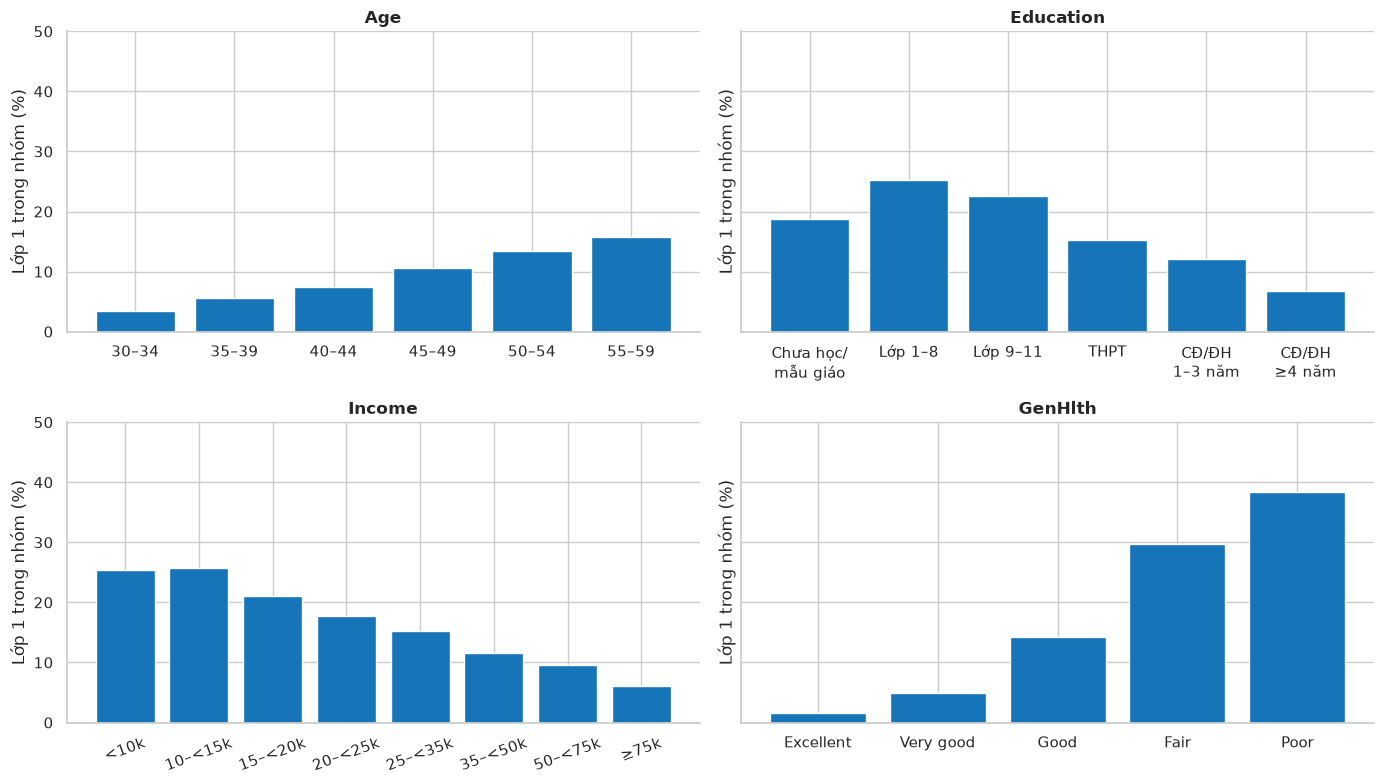

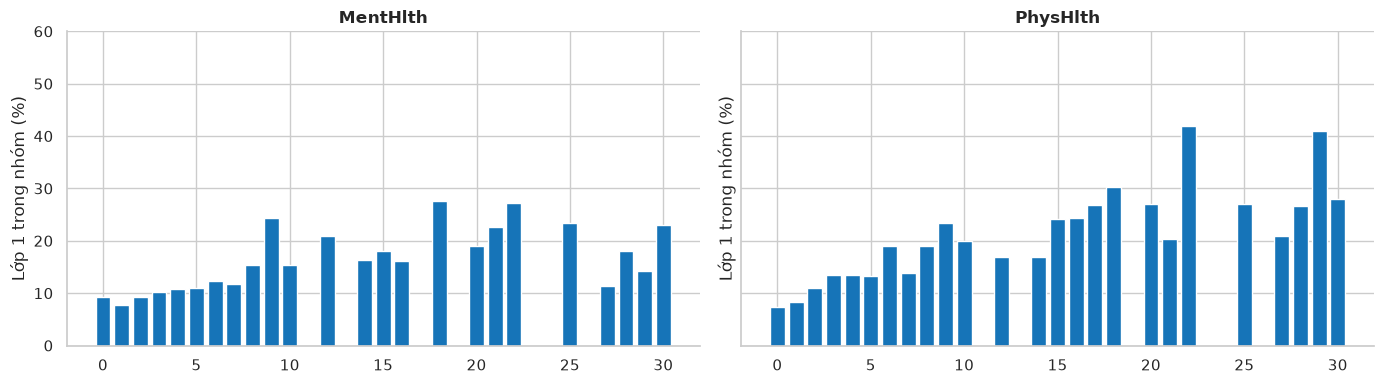

**Quan sát:** tỷ lệ thấp nhất ở tuổi **30–34** (3.49%, n=8,744), cao nhất ở **55–59** (15.77%, n=24,561). Nhóm so sánh các hồ sơ trong mẫu, không theo dõi một người qua thời gian.

### Mức số ngày có n < 30: không vẽ tỷ lệ ở hình chính

,Feature,Days,sample_count,positive_rate
0,MentHlth,11,15,13.33
1,MentHlth,13,21,23.81
2,MentHlth,17,22,18.18
3,MentHlth,19,4,0.00
4,MentHlth,23,17,17.65
5,MentHlth,24,14,28.57
6,MentHlth,26,18,22.22
7,PhysHlth,11,24,16.67
8,PhysHlth,13,24,45.83
9,PhysHlth,19,5,60.00


Nhóm giữ các hồ sơ này trong dữ liệu huấn luyện và giữ đủ mức ở Phụ lục A.2. Hình số ngày chỉ hiển thị tỷ lệ khi n ≥ 30.

**GenHlth = Excellent:** lớp 1 1.59%, n=18,916.

**GenHlth = Poor:** lớp 1 38.43%, n=3,854.

**Income = <10k:** lớp 1 25.37%, n=3,957.

**Income = ≥75k:** lớp 1 6.12%, n=42,597.

In [7]:
fig = plot_rate_grid(list(ORDINAL_DOMAINS), LABEL_MAPS)
save_and_show_figure("eda_05_ordinal_rates", fig)
fig = plot_rate_grid(["MentHlth", "PhysHlth"], LABEL_MAPS, min_count=30)
save_and_show_figure("eda_06_health_day_rates", fig)
low_age = records(
    "SELECT * FROM feature_summary WHERE Feature='Age' AND positive_rate IS NOT NULL ORDER BY positive_rate,level LIMIT 1"
)[0]
high_age = records(
    "SELECT * FROM feature_summary WHERE Feature='Age' AND positive_rate IS NOT NULL ORDER BY positive_rate DESC,level LIMIT 1"
)[0]
note(
    f"**Quan sát:** tỷ lệ thấp nhất ở tuổi **{LABEL_MAPS['Age'][low_age['level']]}** ({low_age['positive_rate']:.2f}%, n={low_age['sample_count']:,}), cao nhất ở **{LABEL_MAPS['Age'][high_age['level']]}** ({high_age['positive_rate']:.2f}%, n={high_age['sample_count']:,}). Nhóm so sánh các hồ sơ trong mẫu, không theo dõi một người qua thời gian."
)
display(Markdown("### Mức số ngày có n < 30: không vẽ tỷ lệ ở hình chính"))
display(
    table(
        "SELECT Feature,level AS Days,sample_count,positive_rate FROM feature_summary WHERE Feature IN ('MentHlth','PhysHlth') AND sample_count BETWEEN 1 AND 29 ORDER BY CASE Feature WHEN 'MentHlth' THEN 0 ELSE 1 END,position"
    ).round(2)
)
note(
    "Nhóm giữ các hồ sơ này trong dữ liệu huấn luyện và giữ đủ mức ở Phụ lục A.2. Hình số ngày chỉ hiển thị tỷ lệ khi n ≥ 30."
)
for feature in ["GenHlth", "Income"]:
    for row in records(
        "SELECT * FROM feature_summary WHERE Feature=? AND (level=(SELECT MIN(level) FROM feature_summary WHERE Feature=?) OR level=(SELECT MAX(level) FROM feature_summary WHERE Feature=?)) ORDER BY position",
        (feature, feature, feature),
    ):
        note(
            f"**{feature} = {LABEL_MAPS[feature][row['level']]}:** lớp 1 {row['positive_rate']:.2f}%, n={row['sample_count']:,}."
        )


### c. BMI theo nhãn

Hai lớp dùng chung ranh giới bin và mỗi lớp có tổng tỷ trọng 100%.
Nhờ đó, người đọc so sánh hình dạng phân bố dù hai lớp có số hồ sơ khác nhau.
Tỷ trọng trong hình này không phải tỷ lệ mắc nhãn 1 tại một mức BMI.


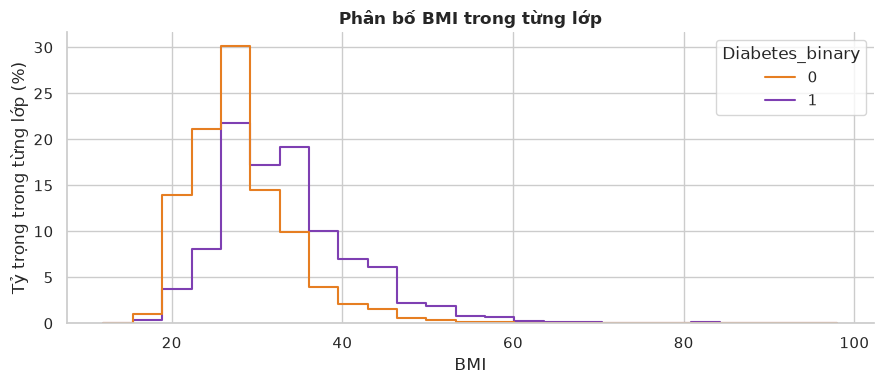

,Diabetes_binary,count,mean,median
0,0,83137,28.28,27.0
1,1,10192,33.60,32.0


Nhóm đọc histogram cùng trung vị và số hồ sơ của từng lớp. Phân bố có thể chồng lấp; nhóm giữ nhãn khảo sát và không suy ra nhãn từ BMI.

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(
    data=df_eda,
    x="BMI",
    hue=TARGET,
    hue_order=[0, 1],
    bins=25,
    stat="percent",
    common_norm=False,
    common_bins=True,
    element="step",
    fill=False,
    palette=PALETTE,
    ax=ax,
)
ax.set(
    title="Phân bố BMI trong từng lớp",
    xlabel="BMI",
    ylabel="Tỷ trọng trong từng lớp (%)",
)
fig.tight_layout()
save_and_show_figure("eda_07_bmi_by_target", fig)

DB.execute(
    "CREATE TABLE bmi_stats AS SELECT Diabetes_binary,COUNT(BMI) AS count,AVG(BMI) AS mean,CAST(NULL AS REAL) AS median FROM train_data GROUP BY Diabetes_binary"
)
for row in records("SELECT Diabetes_binary FROM bmi_stats ORDER BY Diabetes_binary"):
    label = row[TARGET]
    DB.execute(
        "UPDATE bmi_stats SET median=? WHERE Diabetes_binary=?",
        (sql_quantile("BMI", 0.5, "Diabetes_binary=?", (label,)), label),
    )
display(table("SELECT * FROM bmi_stats ORDER BY Diabetes_binary").round(2))
save_table("SELECT * FROM bmi_stats ORDER BY Diabetes_binary", "eda_bmi_by_target")
note(
    "Nhóm đọc histogram cùng trung vị và số hồ sơ của từng lớp. Phân bố có thể chồng lấp; nhóm giữ nhãn khảo sát và không suy ra nhãn từ BMI."
)


## 1.3. Quan hệ kết hợp và tương quan

### a. Tuổi × BMI

Mỗi ô ghi **tỷ lệ lớp 1 và số hồ sơ n**. Ô trống có n=0; nhóm không gán tỷ lệ 0% cho ô thiếu dữ liệu.
Nhóm BMI chỉ phục vụ EDA, không thay thế đặc trưng BMI đưa vào mô hình.

Nhóm đặt trần màu theo tỷ lệ lớn nhất trong bảng, làm tròn lên bội số 5 điểm phần trăm. Thang màu thể hiện khoảng tỷ lệ quan sát, không chạy đến 100%.


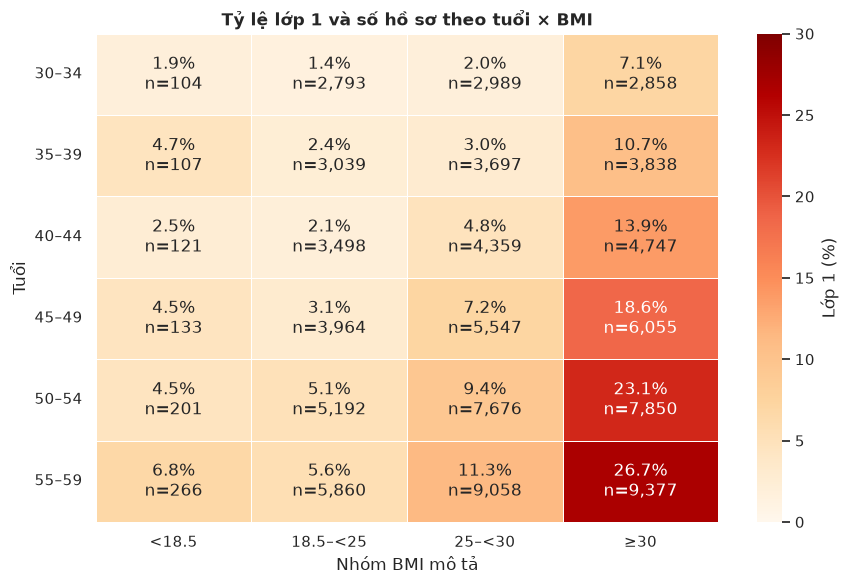

**Quan sát:** tỷ lệ cao nhất ở tuổi **55–59**, BMI **≥30**: **26.72%**, n=**9,377**. Nhóm chưa kiểm định tương tác tuổi × BMI.

In [9]:
bmi_labels = ["<18.5", "18.5–<25", "25–<30", "≥30"]
DB.execute("CREATE TABLE bmi_levels (position INTEGER PRIMARY KEY, label TEXT)")
DB.executemany("INSERT INTO bmi_levels VALUES (?,?)", enumerate(bmi_labels))
DB.execute("""
    CREATE VIEW age_bmi_summary AS
    SELECT a.level AS Age,b.position AS bmi_position,b.label AS BMI_group,
           COALESCE(g.sample_count,0) AS sample_count,g.positive_rate
    FROM feature_levels a CROSS JOIN bmi_levels b LEFT JOIN (
        SELECT Age,bmi_position,COUNT(*) AS sample_count,100.0*AVG(Diabetes_binary) AS positive_rate
        FROM (SELECT Age,Diabetes_binary,CASE WHEN BMI<18.5 THEN 0 WHEN BMI<25 THEN 1 WHEN BMI<30 THEN 2 ELSE 3 END AS bmi_position FROM train_data)
        GROUP BY Age,bmi_position
    ) g ON g.Age=a.level AND g.bmi_position=b.position
    WHERE a.Feature='Age'
""")


def age_bmi_matrix(value):
    return np.array(
        [
            [
                row[value] if row[value] is not None else np.nan
                for row in records(
                    "SELECT * FROM age_bmi_summary WHERE Age=? ORDER BY bmi_position",
                    (age,),
                )
            ]
            for age in ORDINAL_DOMAINS["Age"]
        ]
    )


rate = age_bmi_matrix("positive_rate")
size = age_bmi_matrix("sample_count").astype(int)
annotations = np.array(
    [
        [
            f"{rate[i,j]:.1f}%\nn={size[i,j]:,}" if size[i, j] > 0 else ""
            for j in range(4)
        ]
        for i in range(6)
    ]
)
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(
    rate,
    annot=annotations,
    fmt="",
    cmap="OrRd",
    vmin=0,
    vmax=max(
        5, np.ceil(scalar("SELECT MAX(positive_rate) FROM age_bmi_summary") / 5) * 5
    ),
    linewidths=0.5,
    yticklabels=AGE_LABELS,
    xticklabels=bmi_labels,
    cbar_kws={"label": "Lớp 1 (%)"},
    ax=ax,
)
ax.set(
    title="Tỷ lệ lớp 1 và số hồ sơ theo tuổi × BMI",
    xlabel="Nhóm BMI mô tả",
    ylabel="Tuổi",
)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
save_and_show_figure("eda_08_age_bmi", fig)
save_table("SELECT * FROM age_bmi_summary ORDER BY Age,bmi_position", "age_bmi_summary")
for value, name in [
    ("positive_rate", "age_bmi_positive_rates"),
    ("sample_count", "age_bmi_counts"),
]:
    # Keep the exported rate table on its original 0-1 scale.
    expression = "positive_rate / 100.0" if value == "positive_rate" else value
    columns = ", ".join(
        f"MAX(CASE WHEN bmi_position={j} THEN {expression} END) AS {ident(label)}"
        for j, label in enumerate(bmi_labels)
    )
    save_table(
        f"SELECT Age,{columns} FROM age_bmi_summary GROUP BY Age ORDER BY Age", name
    )

peak = records(
    "SELECT * FROM age_bmi_summary WHERE sample_count>0 ORDER BY positive_rate DESC,Age,bmi_position LIMIT 1"
)[0]
note(
    f"**Quan sát:** tỷ lệ cao nhất ở tuổi **{LABEL_MAPS['Age'][peak['Age']]}**, BMI **{peak['BMI_group']}**: **{peak['positive_rate']:.2f}%**, n=**{peak['sample_count']:,}**. Nhóm chưa kiểm định tương tác tuổi × BMI."
)


### b. Tương quan

Heatmap chỉ hiển thị tam giác dưới để tránh lặp các cặp biến. Pearson trên mã thứ bậc
phụ thuộc cách biểu diễn; bảng Pearson/Spearman đầy đủ nằm ở Phụ lục A.3.
Nhóm không dùng tương quan nhỏ làm lý do duy nhất để loại đặc trưng.


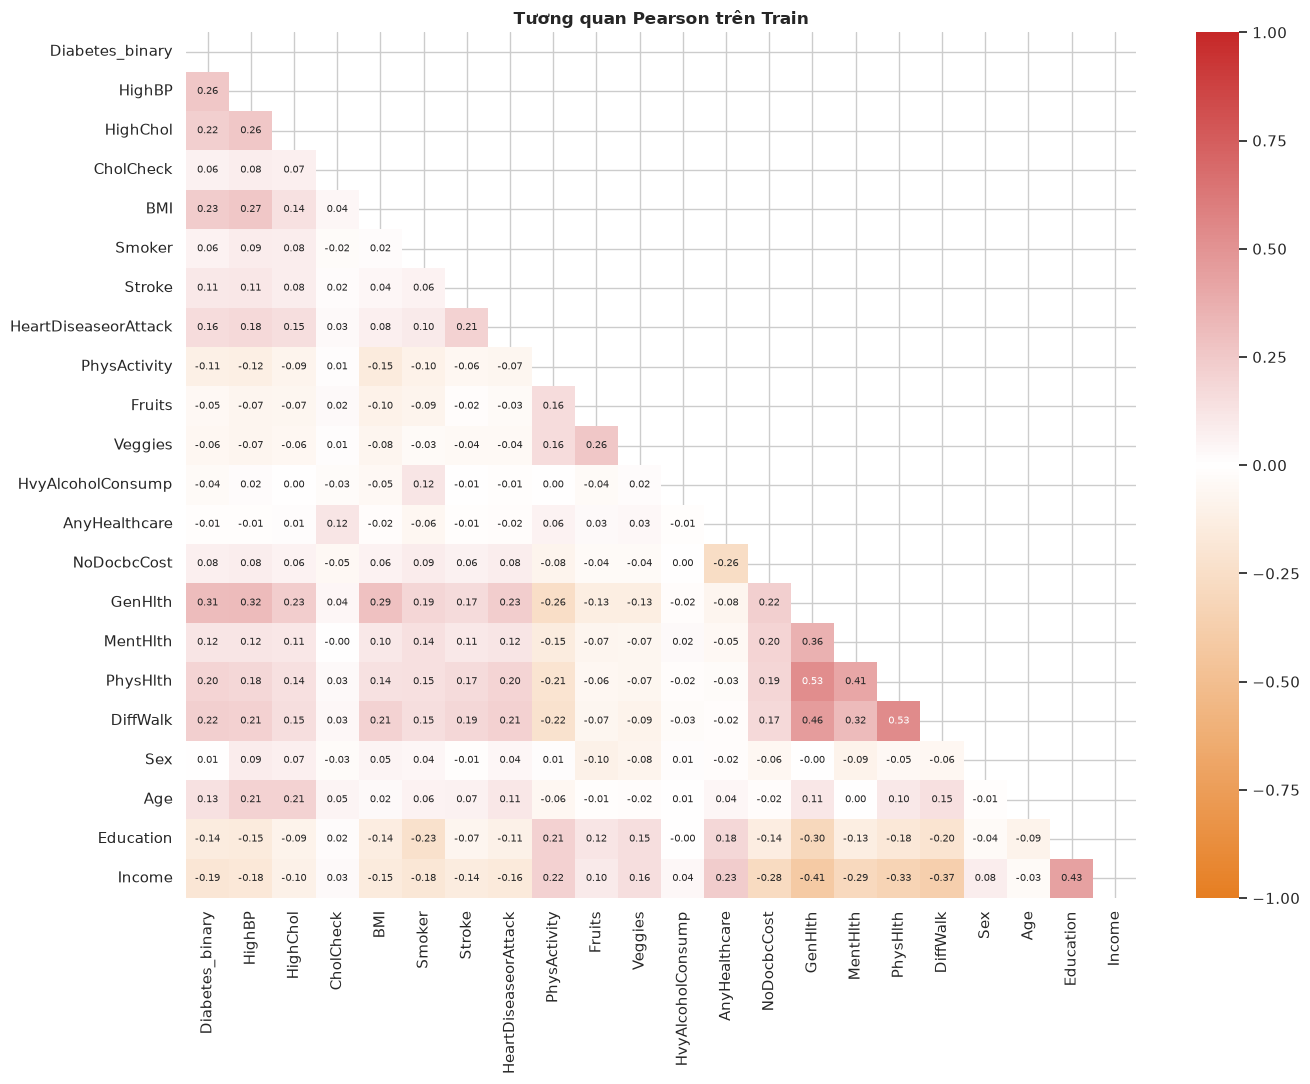

**Quan sát:** **GenHlth** có |Pearson| với nhãn lớn nhất (**r=0.312**). Có **0** cặp đặc trưng đạt |r| > 0,8. Các hệ số mô tả liên hệ từng cặp, không đo đóng góp riêng trong mô hình.

In [10]:
from scipy import stats

correlation_columns = [TARGET] + FEATURES
values = table(f"SELECT {ALL_COLUMNS} FROM train_data ORDER BY row_id").to_numpy(
    dtype=float
)
pearson = np.corrcoef(values, rowvar=False)
spearman = stats.spearmanr(values, axis=0).statistic
DB.execute(
    "CREATE TABLE correlations (feature_a TEXT,feature_b TEXT,Pearson REAL,Spearman REAL,PRIMARY KEY(feature_a,feature_b))"
)
DB.executemany(
    "INSERT INTO correlations VALUES (?,?,?,?)",
    (
        (a, b, float(pearson[i, j]), float(spearman[i, j]))
        for i, a in enumerate(correlation_columns)
        for j, b in enumerate(correlation_columns)
    ),
)
DB.execute(
    f"CREATE VIEW correlation_target AS SELECT f.position,f.Feature,c.Pearson,c.Spearman FROM feature_catalog f JOIN correlations c ON c.feature_a=f.Feature WHERE c.feature_b='{TARGET}'"
)
DB.execute(
    'CREATE VIEW correlation_pairs AS SELECT a.position AS position_a,b.position AS position_b,c.feature_a AS "Feature A",c.feature_b AS "Feature B",c.Pearson FROM correlations c JOIN feature_catalog a ON a.Feature=c.feature_a JOIN feature_catalog b ON b.Feature=c.feature_b WHERE a.position<b.position'
)
mask = np.triu(np.ones(pearson.shape, dtype=bool))
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(
    pearson,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap=CORRELATION_CMAP,
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 7},
    xticklabels=correlation_columns,
    yticklabels=correlation_columns,
    ax=ax,
)
ax.set_title("Tương quan Pearson trên Train")
fig.tight_layout()
save_and_show_figure("eda_09_correlation", fig)
save_table(
    "SELECT Feature,Pearson,Spearman FROM correlation_target ORDER BY position",
    "correlation_target",
)
strongest = records(
    "SELECT * FROM correlation_target ORDER BY ABS(Pearson) DESC,position LIMIT 1"
)[0]
strong_pairs = scalar("SELECT COUNT(*) FROM correlation_pairs WHERE ABS(Pearson)>.8")
note(
    f"**Quan sát:** **{strongest['Feature']}** có |Pearson| với nhãn lớn nhất (**r={strongest['Pearson']:.3f}**). Có **{strong_pairs}** cặp đặc trưng đạt |r| > 0,8. Các hệ số mô tả liên hệ từng cặp, không đo đóng góp riêng trong mô hình."
)


### Kết luận EDA và liên hệ với preprocessing

| Quan sát cần đọc từ kết quả chạy | Ý nghĩa | Quyết định trong dự án |
|---|---|---|
| Tỷ lệ lớp 1 trong biểu đồ nhãn | Accuracy riêng lẻ có thể che khuất việc bỏ sót lớp 1 | Dùng trọng số lớp; đọc Precision, Recall, F1 cùng Accuracy |
| BMI và số ngày có phân bố/thang đo khác nhau | Mô hình tuyến tính cần cách biểu diễn phù hợp | Giữ StandardScaler trên các biến số, fit bằng Train |
| Age, Education, Income, GenHlth là các mức có thứ tự | Mã mức không phải khoảng cách đo bằng nhau | Giữ one-hot cho Logistic Regression, mã thứ bậc cho mô hình cây |
| Điểm BMI ngoài râu boxplot | Giá trị hiếm chưa đủ chứng minh dữ liệu sai | Giữ hồ sơ và nhãn; kiểm tra nguồn trước khi đề xuất xử lý |
| Các nhóm có số hồ sơ khác nhau | Tỷ lệ ở nhóm nhỏ có thể kém ổn định | Đọc tỷ lệ cùng n tại phụ lục; không suy ra nhân quả |

Nhóm giữ chính sách duplicate, các bộ 21/16/18 đặc trưng và thiết kế thử nghiệm hiện tại.


# PART 2: FEATURE ENGINEERING & PREPARATION [3.0 POINTS]

## 2.1. CATEGORICAL ENCODING & FEATURE SCALING

| Nhánh mô hình | Biến số | Mã thứ bậc | Nhị phân | Số cột full21/reduced18/reduced16 |
|---|---|---|---|---|
| Logistic Regression | StandardScaler: BMI, MentHlth, PhysHlth | One-Hot drop-first: Age, Education, Income, GenHlth | Giữ 0/1 | 38 / 35 / 33 |
| Decision Tree, Random Forest, XGBoost | Giữ giá trị gốc | Giữ mã số | Giữ 0/1 | 21 / 18 / 16 |

Tên hiển thị trong EDA không thay thế dữ liệu số. Ở Phần 3, scaler/encoder chỉ fit trên Train, sau đó transform Test. Các cây không cần chuẩn hóa cùng thang đo vì phân nhánh theo ngưỡng của từng feature. Dùng trọng số lớp theo mục 2.2.f; giữ nguyên hồ sơ, không resample hoặc chọn ngưỡng.


In [11]:
def make_preprocessor(feature_set="full_21", family="linear"):
    cols = FEATURE_SETS[feature_set]
    numeric = [c for c in NUMERIC_FEATURES if c in cols]
    ordinal = [c for c in ORDINAL_DOMAINS if c in cols]
    binary = [c for c in cols if c not in numeric + ordinal]

    if family == "linear":
        transforms = [
            ("numeric", StandardScaler(), numeric),
            (
                "ordinal",
                OneHotEncoder(
                    categories=[ORDINAL_DOMAINS[c] for c in ordinal],
                    drop="first",
                    handle_unknown="error",
                    sparse_output=False,
                ),
                ordinal,
            ),
            ("binary", "passthrough", binary),
        ]
    elif family == "tree":
        transforms = [("features", "passthrough", cols)]
    else:
        raise ValueError(f"Family không hợp lệ: {family}")

    return ColumnTransformer(transforms, remainder="drop")


def make_pipeline(model, feature_set="full_21", family="linear"):
    return Pipeline(
        [
            ("preprocess", make_preprocessor(feature_set, family)),
            ("model", clone(model)),
        ]
    )


print("Đã thiết kế xong các Pipeline tiền xử lý độc lập cho họ Tuyến tính và họ Cây!")


Đã thiết kế xong các Pipeline tiền xử lý độc lập cho họ Tuyến tính và họ Cây!


In [12]:
DB.execute(
    'CREATE TABLE preprocessor_demo (position INTEGER,FeatureSet TEXT,Family TEXT,"Fit rows" INTEGER,"Validation rows" INTEGER,Columns INTEGER)'
)
demo_rows = []
for feature_set_name in ["full_21", "reduced_18", "reduced_16"]:
    for family in ["linear", "tree"]:
        demo = make_preprocessor(feature_set_name, family)
        fit_data = table(
            f"SELECT {FEATURE_COLUMNS} FROM clean_data JOIN split_manifest USING(row_id) WHERE split='train' AND cv_fold!=0 ORDER BY row_id",
            dtype="int16",
        )
        val_data = table(
            f"SELECT {FEATURE_COLUMNS} FROM clean_data JOIN split_manifest USING(row_id) WHERE split='train' AND cv_fold=0 ORDER BY row_id",
            dtype="int16",
        )
        fit_values = demo.fit_transform(fit_data)
        val_values = demo.transform(val_data)
        expected = {
            ("full_21", "linear"): 38,
            ("reduced_18", "linear"): 35,
            ("reduced_16", "linear"): 33,
            ("full_21", "tree"): 21,
            ("reduced_18", "tree"): 18,
            ("reduced_16", "tree"): 16,
        }[(feature_set_name, family)]
        assert fit_values.shape[1] == val_values.shape[1] == expected
        row = (
            len(demo_rows),
            feature_set_name,
            family,
            fit_values.shape[0],
            val_values.shape[0],
            expected,
        )
        demo_rows.append(row)
        DB.execute("INSERT INTO preprocessor_demo VALUES (?,?,?,?,?,?)", row)
display(
    table(
        'SELECT FeatureSet,Family,"Fit rows","Validation rows",Columns FROM preprocessor_demo ORDER BY position'
    )
)
save_table(
    'SELECT FeatureSet,Family,"Fit rows","Validation rows",Columns FROM preprocessor_demo ORDER BY position',
    "preprocessor_demo",
)


,FeatureSet,Family,Fit rows,Validation rows,Columns
0,full_21,linear,74662,18667,38
1,full_21,tree,74662,18667,21
2,reduced_18,linear,74662,18667,35
3,reduced_18,tree,74662,18667,18
4,reduced_16,linear,74662,18667,33
5,reduced_16,tree,74662,18667,16


## 2.2. TRAIN-TEST SPLIT & FEATURE SELECTION

### a. Tập Train/Test và phạm vi lựa chọn

Tạo manifest riêng cho dữ liệu 30–59, xấp xỉ 80/20 bằng StratifiedGroupKFold; số lượng thực tế nằm ở bảng split đầu notebook. Khóa nhóm gồm 21 feature, không có nhãn. Tạo 5 fold theo nhóm trong Train, kiểm tra không giao nhóm với Test hoặc giữa fit/validation. Manifest được kiểm tra bằng SHA256 dữ liệu khi chạy lại.

Tương quan, VIF, ANOVA và Chi-square chỉ dùng Train để mô tả/xếp hạng. Không dùng Test để quyết định giữ/bỏ biến. Nếu thử bộ biến chọn bằng selector, cần fit selector riêng trong mỗi fold; bản này đối chiếu ba bộ 21/18/16 theo thiết kế hiện có. Nhóm xem hai bộ rút gọn là giả thuyết phân tích độ nhạy, chưa kết luận các biến bị bỏ là vô ích. Nhóm không dùng kết quả Test để cập nhật danh sách biến trong lượt đánh giá này.

### b. Lựa chọn đặc trưng bằng tương quan

Dùng kết quả tương quan ở mục 1.3.b và bảng Phụ lục A.3; không vẽ lại biểu đồ. Tương quan nhỏ chưa chứng minh feature vô ích khi có quan hệ phi tuyến hoặc tương tác.


### c. VIF: kiểm tra phụ thuộc tuyến tính giữa các feature

Tính VIF cho **21 biến X, không đưa nhãn y vào**. Với dữ liệu được định tâm và chuẩn hóa, VIF là đường chéo của nghịch đảo ma trận tương quan giữa X, tương đương hồi quy từng feature theo các feature còn lại có hệ số chặn. Mã thứ bậc vẫn được xem tuyến tính trong phép kiểm tra này, nên VIF chỉ là chỉ báo bổ sung cho phiên bản X số gốc.

,Feature,VIF
0,GenHlth,1.826
1,PhysHlth,1.741
2,DiffWalk,1.612
3,Income,1.595
4,Education,1.339
5,MentHlth,1.307
6,HighBP,1.260
7,NoDocbcCost,1.174
8,BMI,1.164
9,HighChol,1.151


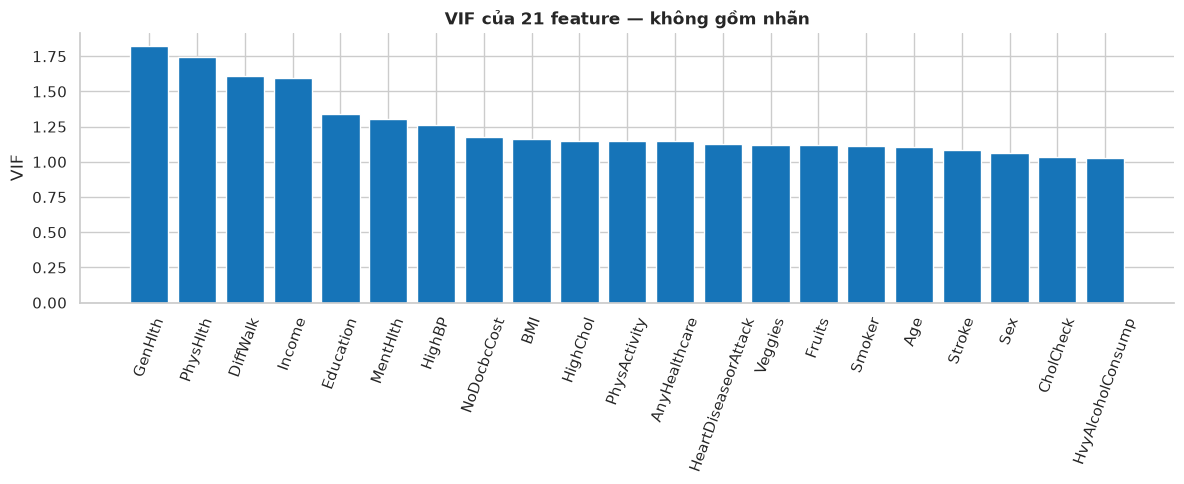

**Nhận xét:** VIF cao nhất là **GenHlth = 1.826**. VIF mô tả phụ thuộc tuyến tính giữa các feature; nhóm không loại biến từ riêng bảng này.

In [13]:
vif_values = X_train.to_numpy(dtype=float)
standardized = (vif_values - vif_values.mean(axis=0)) / vif_values.std(axis=0, ddof=0)
vif_correlation = np.corrcoef(standardized, rowvar=False)
assert np.linalg.matrix_rank(vif_correlation) == len(FEATURES)
vif = np.diag(np.linalg.inv(vif_correlation))
assert np.all(vif >= 1 - 1e-8)
DB.execute("CREATE TABLE vif_results (Feature TEXT PRIMARY KEY,VIF REAL)")
DB.executemany(
    "INSERT INTO vif_results VALUES (?,?)",
    ((feature, float(value)) for feature, value in zip(FEATURES, vif)),
)
VIF_SQL = "SELECT Feature,VIF FROM vif_results ORDER BY VIF DESC,Feature"
display(table(VIF_SQL).round(3))
save_table(VIF_SQL, "ref_vif")
values = records(VIF_SQL)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar([r["Feature"] for r in values], [r["VIF"] for r in values], color=BLUE)
ax.set(title="VIF của 21 feature — không gồm nhãn", ylabel="VIF")
ax.tick_params(axis="x", rotation=70)
fig.tight_layout()
save_and_show_figure("ref_12_vif", fig)
note(
    f"**Nhận xét:** VIF cao nhất là **{values[0]['Feature']} = {values[0]['VIF']:.3f}**. VIF mô tả phụ thuộc tuyến tính giữa các feature; nhóm không loại biến từ riêng bảng này."
)


### d. ANOVA F-score và Chi-square: xếp hạng đơn biến

Tham khảo `SelectKBest`/`f_classif` và `chi2` của notebook nguồn, nhưng giữ tên feature và xuất đầy đủ điểm/rank. ANOVA F-score so sánh trung bình feature giữa hai lớp; với biến rời rạc/nhị phân đây chỉ là xếp hạng khám phá, chưa xác nhận các giả định kiểm định. `chi2` yêu cầu đầu vào không âm; các điểm trên biến số phụ thuộc thang đo nên không được diễn giải như độ quan trọng độc lập. Hai phép tính dùng **X số gốc trước StandardScaler**, chỉ trên Train. P-value chưa tính trọng số/thiết kế khảo sát BRFSS.

,Feature,Pearson,ANOVA_F,ANOVA_p,Chi2_score,Chi2_p,ANOVA_p_BH,Chi2_p_BH,ANOVA_rank,Chi2_rank
0,GenHlth,0.31228,10084.84243,0.00000,4178.37856,0.00000,0.00000,0.00000,1,5
1,HighBP,0.26173,6863.41338,0.00000,4411.50005,0.00000,0.00000,0.00000,2,4
2,BMI,0.23479,5485.64434,0.00000,8932.31082,0.00000,0.00000,0.00000,3,3
3,DiffWalk,0.22212,4843.50659,0.00000,4050.82184,0.00000,0.00000,0.00000,4,6
4,HighChol,0.22004,4748.65387,0.00000,2984.79118,0.00000,0.00000,0.00000,5,7
5,PhysHlth,0.19772,3796.85915,0.00000,64767.01188,0.00000,0.00000,0.00000,6,1
6,Income,-0.19368,3637.26598,0.00000,2316.65237,0.00000,0.00000,0.00000,7,8
7,HeartDiseaseorAttack,0.16058,2470.24265,0.00000,2302.93575,0.00000,0.00000,0.00000,8,9
8,Education,-0.14063,1882.97812,0.00000,333.70360,0.00000,0.00000,0.00000,9,13
9,Age,0.13452,1720.00482,0.00000,747.96251,0.00000,0.00000,0.00000,10,11


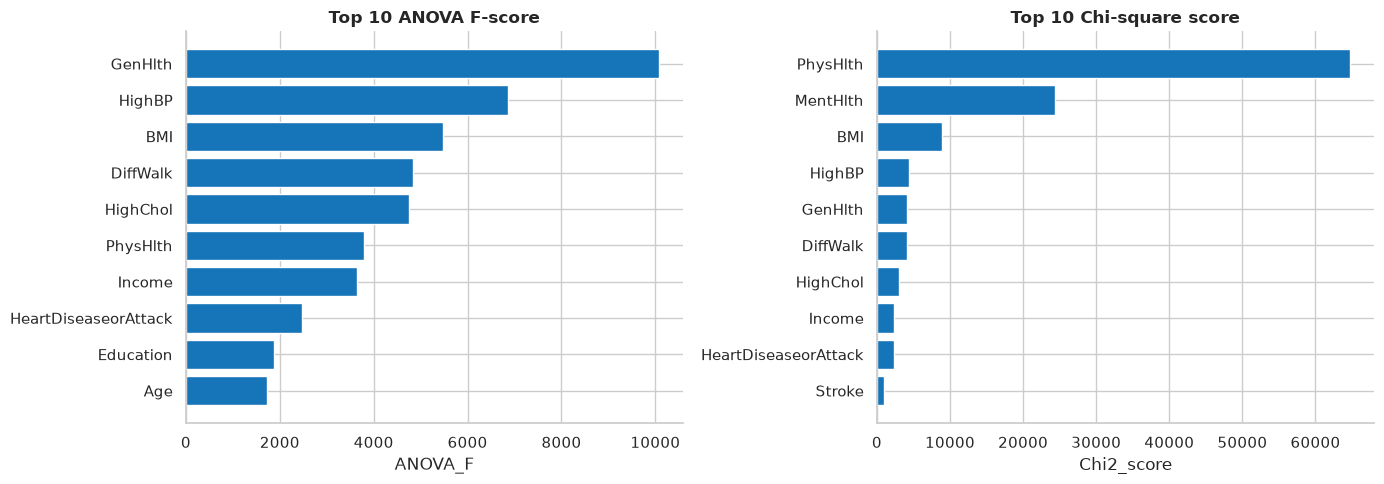

**Nhận xét:** top 5 ANOVA: **GenHlth, HighBP, BMI, DiffWalk, HighChol**; top 5 Chi-square: **PhysHlth, MentHlth, BMI, HighBP, GenHlth**. Nhóm giữ các kiểm định bằng scikit-learn/scipy, lập bảng và xếp hạng bằng SQL. Nhóm không tự động chọn top 16; p nhỏ không chứng minh ý nghĩa thực tiễn lớn.

In [14]:
from sklearn.feature_selection import f_classif, chi2

assert scalar("SELECT MIN(minimum) FROM data_summary WHERE Feature!=?", (TARGET,)) >= 0
f_scores, f_p = f_classif(X_train.to_numpy(), y_train)
chi_scores, chi_p = chi2(X_train.to_numpy(), y_train)
f_bh = stats.false_discovery_control(f_p, method="bh")
chi_bh = stats.false_discovery_control(chi_p, method="bh")
DB.execute(
    "CREATE TABLE feature_tests (Feature TEXT PRIMARY KEY,ANOVA_F REAL,ANOVA_p REAL,Chi2_score REAL,Chi2_p REAL,ANOVA_p_BH REAL,Chi2_p_BH REAL)"
)
DB.executemany(
    "INSERT INTO feature_tests VALUES (?,?,?,?,?,?,?)",
    (
        (
            feature,
            float(f_scores[i]),
            float(f_p[i]),
            float(chi_scores[i]),
            float(chi_p[i]),
            float(f_bh[i]),
            float(chi_bh[i]),
        )
        for i, feature in enumerate(FEATURES)
    ),
)
DB.execute(
    "CREATE VIEW feature_ranking AS SELECT f.position,t.*,c.Pearson,RANK() OVER(ORDER BY ANOVA_F DESC) AS ANOVA_rank,RANK() OVER(ORDER BY Chi2_score DESC) AS Chi2_rank FROM feature_tests t JOIN correlation_target c USING(Feature) JOIN feature_catalog f USING(Feature)"
)
FEATURE_RANKING_SQL = "SELECT Feature,Pearson,ANOVA_F,ANOVA_p,Chi2_score,Chi2_p,ANOVA_p_BH,Chi2_p_BH,ANOVA_rank,Chi2_rank FROM feature_ranking"
display(table(FEATURE_RANKING_SQL + " ORDER BY ANOVA_rank,position").round(5))
save_table(FEATURE_RANKING_SQL + " ORDER BY position", "ref_feature_ranking")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [
    (axes[0], "ANOVA_F", "Top 10 ANOVA F-score"),
    (axes[1], "Chi2_score", "Top 10 Chi-square score"),
]:
    values = records(
        f"SELECT * FROM (SELECT Feature,{metric},position FROM feature_ranking ORDER BY {metric} DESC,position LIMIT 10) ORDER BY {metric},position"
    )
    ax.barh([r["Feature"] for r in values], [r[metric] for r in values], color=BLUE)
    ax.set(title=title, xlabel=metric)
fig.tight_layout()
save_and_show_figure("ref_13_feature_ranking", fig)
anova_top = ", ".join(
    r["Feature"]
    for r in records(
        "SELECT Feature FROM feature_ranking ORDER BY ANOVA_rank,position LIMIT 5"
    )
)
chi_top = ", ".join(
    r["Feature"]
    for r in records(
        "SELECT Feature FROM feature_ranking ORDER BY Chi2_rank,position LIMIT 5"
    )
)
note(
    f"**Nhận xét:** top 5 ANOVA: **{anova_top}**; top 5 Chi-square: **{chi_top}**. Nhóm giữ các kiểm định bằng scikit-learn/scipy, lập bảng và xếp hạng bằng SQL. Nhóm không tự động chọn top 16; p nhỏ không chứng minh ý nghĩa thực tiễn lớn."
)


### e. Quyết định giữ feature và đối chiếu 21/16

Notebook EDA tham khảo và file Phần 3 mới cùng đề xuất thử bỏ Fruits, Veggies, Sex, CholCheck, AnyHealthcare. Giữ các phương án **full_21/reduced_16, bổ sung reduced_18 ở Phần 3** như các cấu hình định trước rồi ghi nhận bốn metrics trên Test ở Phần 3; không tự chọn top-k từ bảng toàn Train và coi đó là kiểm chứng độc lập. Bảng dưới mô tả vai trò từng biến, chưa khẳng định bộ nào tốt hơn.


**Giải thích ba bộ biến:** Nhóm dùng 21 biến làm mốc đầy đủ. Bộ 16 bỏ Fruits, Veggies, Sex, CholCheck và AnyHealthcare theo thiết kế đối chiếu hiện có. Bộ 18 thử bỏ Stroke, Sex và PhysHlth để xem hiệu năng khi nhóm không cung cấp ba đặc trưng này. Đây là giả thuyết ablation, chưa phải kết quả của một thuật toán chọn biến trên Train.

Stroke và PhysHlth có liên hệ với nhãn trên Train; vì vậy nhóm không gọi chúng là biến dư thừa. Nhóm giữ chúng trong bộ 21 và dùng bảng tương quan, VIF, ANOVA/Chi-square để mô tả bằng chứng. Nhóm chưa có căn cứ cho rằng bộ 18 tốt hơn trước khi đánh giá; Ongoing 3 cần kiểm tra lựa chọn bằng validation.


**Nguồn gốc giả thuyết bộ 18 từ nhật ký thử nghiệm của nhóm:** Trong 84 lượt fit thăm dò ở phiên bản baseline không trọng số trước đây, nhóm lần lượt bỏ riêng từng feature trên bốn mô hình với cùng split và tham số. Bỏ Stroke làm F1 tăng ở 4/4 mô hình, Recall tăng ở 3/4 và không đổi ở một mô hình. Bỏ Sex hoặc PhysHlth làm Recall và F1 cùng tăng ở 3/4 mô hình, nhưng giảm ở mô hình còn lại. Nhóm vì vậy đề xuất thử bỏ đồng thời ba biến để kiểm tra tính đơn giản của bộ 18.

Đây là lý do đưa ra phương án đối chiếu, không chứng minh các biến dư thừa. Các thử nghiệm cũ không dùng trọng số, còn 24 cấu hình hiện tại có trọng số; không suy diễn rằng lợi ích loại biến phải giữ nguyên. Không cộng tác động bỏ riêng thành tác động bỏ đồng thời. Test đã được xem trong quá trình thăm dò, nên bộ 18 không được coi là lựa chọn độc lập với Test hoặc feature selection trên Train.


In [15]:
DB.execute("""
    CREATE VIEW feature_decision AS
    SELECT f.position,f.Feature,
      CASE WHEN EXISTS(SELECT 1 FROM feature_sets s WHERE s.Feature=f.Feature AND s.name='full_21') THEN 'Giữ' ELSE 'Bỏ trong giả thuyết đối chiếu' END AS full_21,
      CASE WHEN EXISTS(SELECT 1 FROM feature_sets s WHERE s.Feature=f.Feature AND s.name='reduced_18') THEN 'Giữ' ELSE 'Bỏ trong giả thuyết đối chiếu' END AS reduced_18,
      CASE WHEN EXISTS(SELECT 1 FROM feature_sets s WHERE s.Feature=f.Feature AND s.name='reduced_16') THEN 'Giữ' ELSE 'Bỏ trong giả thuyết đối chiếu' END AS reduced_16
    FROM feature_catalog f
""")
display(
    table(
        "SELECT Feature,full_21,reduced_18,reduced_16 FROM feature_decision ORDER BY position"
    )
)
save_table(
    "SELECT Feature,full_21,reduced_18,reduced_16 FROM feature_decision ORDER BY position",
    "merged_feature_decision",
)
assert [
    scalar("SELECT COUNT(*) FROM feature_sets WHERE name=?", (name,))
    for name in FEATURE_SET_ORDER
] == [18, 16, 21]


,Feature,full_21,reduced_18,reduced_16
0,HighBP,Giữ,Giữ,Giữ
1,HighChol,Giữ,Giữ,Giữ
2,CholCheck,Giữ,Giữ,Bỏ trong giả thuyết đối chiếu
3,BMI,Giữ,Giữ,Giữ
4,Smoker,Giữ,Giữ,Giữ
5,Stroke,Giữ,Bỏ trong giả thuyết đối chiếu,Giữ
6,HeartDiseaseorAttack,Giữ,Giữ,Giữ
7,PhysActivity,Giữ,Giữ,Giữ
8,Fruits,Giữ,Giữ,Bỏ trong giả thuyết đối chiếu
9,Veggies,Giữ,Giữ,Bỏ trong giả thuyết đối chiếu


**STUDENT COMMENTS — 2.2:** Ba bộ 21/18/16 dùng cùng Train/Test từ manifest hiện có. Các fold vẫn được lưu trong phần chuẩn bị dữ liệu nhưng không dùng để chạy CV mô hình ở Phần 3. Khóa nhóm trên 21 feature gốc; các bộ rút gọn vẫn có thể có hồ sơ trùng trên riêng các feature giữ lại giữa các nhóm gốc. Nhóm chưa khẳng định bộ rút gọn tốt hơn bộ đầy đủ.

### f. Xử lý mất cân bằng bằng trọng số lớp

Nhóm chọn một phương pháp: **class weighting**. Logistic Regression, Decision Tree và Random Forest
dùng `class_weight="balanced"`. XGBoost dùng `scale_pos_weight = n0 / n1`, tính từ nhãn
của đúng Train đang fit (giữ hoặc loại duplicate). Nhóm không dùng nhãn Test để tính trọng số.

Với scikit-learn, trọng số mỗi lớp là `N / (2 * n_class)`. XGBoost giữ trọng số lớp âm bằng 1
và điều chỉnh lớp dương; hai cơ chế không hoàn toàn tương đương. Đây là trọng số huấn luyện,
không phải trọng số khảo sát BRFSS.

Nhóm chạy **24 cấu hình có trọng số**: ba bộ biến × hai cách xử lý duplicate × bốn mô hình. Nhóm giữ preprocessing, seed, tham số và manifest; không resample, tuning hoặc tìm ngưỡng. Precision, Recall và F1 tính cho lớp 1; Accuracy tính trên toàn Test.

Nhóm đối chiếu cả 24 cấu hình trên cùng Test không duplicate và đọc cả bốn chỉ số. Vì nhóm không chạy cấu hình chưa trọng số, nhóm chưa đo tác động riêng của class weighting. Đây là đánh giá khám phá trên Test đã xem; nhóm dành lựa chọn và fine-tuning cho validation ở Ongoing 3.


# PART 3: MODEL BUILDING & EVALUATION [3.0 POINTS]

## 3.1. Sáu trường hợp dữ liệu và feature

Ba bộ 18/16/21 feature × hai bản giữ duplicate/không duplicate, mỗi trường hợp chạy Logistic Regression, Decision Tree, Random Forest và XGBoost. Nhóm chạy 24 cấu hình dùng trọng số lớp: 3 bộ feature × 2 cách xử lý duplicate × 4 mô hình. Logistic Regression, Decision Tree và Random Forest dùng class_weight="balanced"; XGBoost dùng scale_pos_weight=n0/n1 từ đúng Train. Nhóm giữ các tham số còn lại, dùng predict() và dành tuning cho Ongoing 3. Bốn metrics là Accuracy, Precision, Recall và F1, ba chỉ số sau tính cho lớp 1.

Bộ 18 bỏ Stroke, Sex, PhysHlth. Bộ 16 bỏ Fruits, Veggies, Sex, CholCheck, AnyHealthcare. Bộ 21 giữ đủ feature. Loại duplicate theo toàn bộ 22 cột của dữ liệu sạch (21 feature + nhãn), <b>trước</b> khi giảm feature; không xóa những hồ sơ chỉ giống nhau trên bộ rút gọn. Dòng cùng feature nhưng khác nhãn vẫn giữ và ở cùng nhóm split.

Giữ cách phân bổ nhóm hồ sơ của manifest hiện có cho cả hai bản; bản không duplicate là tập con của mỗi train/test hiện tại. Phần 1-2 vẫn dùng bản chính giữ duplicate như trước.


In [16]:
from xgboost import XGBClassifier
from threadpoolctl import threadpool_limits

RESULTS = BASE / "weighted_24_results"
RESULTS.mkdir(exist_ok=True)
DB.execute("""
    CREATE VIEW dataset_split_summary AS
    SELECT r.Dataset,r.split AS Split,COUNT(*) AS Rows,
           SUM(d.Diabetes_binary=0) AS "Class 0",SUM(d.Diabetes_binary=1) AS "Class 1",
           100.0*AVG(d.Diabetes_binary) AS "Class 1 (%)"
    FROM dataset_rows r JOIN clean_data d USING(row_id) GROUP BY r.Dataset,r.split
""")
display(table("SELECT * FROM dataset_split_summary ORDER BY Dataset,Split DESC"))
export_sql(
    "SELECT * FROM dataset_split_summary ORDER BY Dataset,Split DESC",
    RESULTS / "dataset_split_summary.csv",
)
export_sql(
    "SELECT s.row_id,s.group_id,s.split,CASE WHEN d.row_id IS NULL THEN 0 ELSE 1 END AS retained_no_duplicates FROM split_manifest s LEFT JOIN clean_dedup d USING(row_id) ORDER BY s.row_id",
    RESULTS / "six_case_manifest.csv",
)
datasets = ["keep_duplicates", "no_duplicates"]
training_data = {}
for dataset in datasets:
    training_data[dataset] = {
        "X": table(
            f"SELECT {FEATURE_COLUMNS} FROM clean_data JOIN dataset_rows r USING(row_id) WHERE r.Dataset=? AND r.split='train' ORDER BY row_id",
            (dataset,),
            dtype="int16",
        ),
        "y": np.array(
            [
                r[TARGET]
                for r in records(
                    "SELECT Diabetes_binary FROM clean_data JOIN dataset_rows r USING(row_id) WHERE r.Dataset=? AND r.split='train' ORDER BY row_id",
                    (dataset,),
                )
            ],
            dtype=np.int16,
        ),
    }
prediction_data = table(
    f"SELECT {FEATURE_COLUMNS} FROM clean_data JOIN split_manifest USING(row_id) WHERE split='test' ORDER BY row_id",
    dtype="int16",
)
test_ids = [
    r["row_id"]
    for r in records(
        "SELECT row_id FROM split_manifest WHERE split='test' ORDER BY row_id"
    )
]
common_test_rows = scalar(
    "SELECT COUNT(*) FROM dataset_rows WHERE Dataset='no_duplicates' AND split='test'"
)
assert common_test_rows == 20568
algorithms = [
    (
        "LogisticRegression",
        "linear",
        LogisticRegression(C=1.0, solver="lbfgs", max_iter=1500, random_state=SEED),
    ),
    (
        "DecisionTree",
        "tree",
        DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=SEED),
    ),
    (
        "RandomForest",
        "tree",
        RandomForestClassifier(
            n_estimators=100,
            max_depth=16,
            min_samples_leaf=20,
            n_jobs=4,
            random_state=SEED,
        ),
    ),
    (
        "XGBoost",
        "tree",
        XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            n_jobs=4,
            random_state=SEED,
            eval_metric="logloss",
        ),
    ),
]
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]


WEIGHTING_MODES = ("balanced",)
EXPECTED_CONFIGS = len(FEATURE_SET_ORDER) * len(datasets) * len(algorithms)
DB.execute("""
    CREATE VIEW training_class_weights AS
    SELECT Dataset, "Class 0" AS TrainClass0,"Class 1" AS TrainClass1,
           1.0*Rows/(2*"Class 0") AS BalancedWeight0,
           1.0*Rows/(2*"Class 1") AS BalancedWeight1,
           1.0*"Class 0"/"Class 1" AS NegativePositiveRatio
    FROM dataset_split_summary WHERE Split='train'
""")


def training_class_weights(dataset):
    weights = records(
        "SELECT TrainClass0,TrainClass1,BalancedWeight0,BalancedWeight1,NegativePositiveRatio FROM training_class_weights WHERE Dataset=?",
        (dataset,),
    )[0]
    if weights["TrainClass0"] == 0 or weights["TrainClass1"] == 0:
        raise ValueError("Train phải có đủ hai lớp.")
    return weights


def configure_class_weighting(model, dataset):
    configured = clone(model)
    weights = training_class_weights(dataset)
    if "class_weight" in configured.get_params():
        configured.set_params(class_weight="balanced")
    elif "scale_pos_weight" in configured.get_params():
        configured.set_params(scale_pos_weight=weights["NegativePositiveRatio"])
    else:
        raise ValueError("Mô hình không hỗ trợ cơ chế trọng số.")
    return configured, weights


display(table("SELECT * FROM training_class_weights ORDER BY Dataset").round(6))
export_sql(
    "SELECT * FROM training_class_weights ORDER BY Dataset",
    RESULTS / "training_class_weights.csv",
)


,Dataset,Split,Rows,Class 0,Class 1,Class 1 (%)
0,keep_duplicates,train,93329,83137,10192,10.920507
1,keep_duplicates,test,23333,20784,2549,10.924442
2,no_duplicates,train,82258,72104,10154,12.344088
3,no_duplicates,test,20568,18029,2539,12.344419


,Dataset,TrainClass0,TrainClass1,BalancedWeight0,BalancedWeight1,NegativePositiveRatio
0,keep_duplicates,83137,10192,0.561296,4.578542,8.157084
1,no_duplicates,72104,10154,0.570412,4.050522,7.101044


## 3.2. Chạy 24 cấu hình có trọng số

Nhóm fit preprocessing và mô hình trên Train tương ứng, tính trọng số từ nhãn của đúng Train.
Mỗi cấu hình dự đoán trên Test hiện có; nhóm xuất chỉ số trên Test tương ứng và Test chung gồm 20.568 hồ sơ đã loại duplicate.
Nhóm dùng `predict()` với ngưỡng mặc định, lưu tiến độ sau mỗi lần fit.


In [17]:
from sklearn.metrics import confusion_matrix


def fit_and_predict_configuration(dataset, model, *, feature_set_name, family):
    configured, weights = configure_class_weighting(model, dataset)
    pipeline = make_pipeline(configured, feature_set=feature_set_name, family=family)
    with threadpool_limits(limits=4):
        pipeline.fit(training_data[dataset]["X"], training_data[dataset]["y"])
        predicted = pipeline.predict(prediction_data)
    return predicted, pipeline.named_steps["model"].get_params(), weights


def verify_weighting_parameters(params, weights):
    if "class_weight" in params:
        assert params["class_weight"] == "balanced"
    else:
        assert np.isclose(params["scale_pos_weight"], weights["NegativePositiveRatio"])


DB.execute(
    'CREATE TABLE configurations (Config TEXT PRIMARY KEY,Dataset TEXT,"Feature set" TEXT,Features INTEGER,Model TEXT,Weighting TEXT,TrainRows INTEGER,TrainClass0 INTEGER,TrainClass1 INTEGER,BalancedWeight0 REAL,BalancedWeight1 REAL,NegativePositiveRatio REAL)'
)
DB.execute(
    "CREATE TABLE predictions (Config TEXT,row_id INTEGER,predicted INTEGER,PRIMARY KEY(Config,row_id))"
)
DB.execute(
    'CREATE TABLE metric_results (Config TEXT,TestView TEXT,TestRows INTEGER,Accuracy REAL,Precision REAL,Recall REAL,"F1-score" REAL,PRIMARY KEY(Config,TestView))'
)
DB.execute(
    """CREATE VIEW native_results AS SELECT c.*,m.TestRows,m.Accuracy,m.Precision,m.Recall,m."F1-score" FROM configurations c JOIN metric_results m USING(Config) WHERE m.TestView='native'"""
)
DB.execute(
    """CREATE VIEW common_results AS SELECT c.*,m.TestRows,m.Accuracy,m.Precision,m.Recall,m."F1-score" FROM configurations c JOIN metric_results m USING(Config) WHERE m.TestView='common'"""
)
run_parameters = {}
for feature_set_name in FEATURE_SET_ORDER:
    for dataset in datasets:
        for name, family, model in algorithms:
            key = f"{feature_set_name}__{dataset}__{name}__balanced"
            predicted, params, weights = fit_and_predict_configuration(
                dataset, model, feature_set_name=feature_set_name, family=family
            )
            verify_weighting_parameters(params, weights)
            DB.execute(
                "INSERT INTO configurations VALUES (?,?,?,?,?,?,?,?,?,?,?,?)",
                (
                    key,
                    dataset,
                    feature_set_name,
                    len(FEATURE_SETS[feature_set_name]),
                    name,
                    "balanced",
                    weights["TrainClass0"] + weights["TrainClass1"],
                    *weights.values(),
                ),
            )
            DB.executemany(
                "INSERT INTO predictions VALUES (?,?,?)",
                ((key, row_id, int(pred)) for row_id, pred in zip(test_ids, predicted)),
            )
            for test_view, evaluation_dataset in [
                ("native", dataset),
                ("common", "no_duplicates"),
            ]:
                DB.execute(
                    """
                    INSERT INTO metric_results
                    SELECT ?,?,n,
                        1.0*(tp+tn)/n,
                        COALESCE(1.0*tp/NULLIF(tp+fp,0),0),
                        COALESCE(1.0*tp/NULLIF(tp+fn,0),0),
                        COALESCE(2.0*tp/NULLIF(2*tp+fp+fn,0),0)
                    FROM (
                        SELECT COUNT(*) AS n,
                          SUM(d.Diabetes_binary=1 AND p.predicted=1) AS tp,
                          SUM(d.Diabetes_binary=0 AND p.predicted=0) AS tn,
                          SUM(d.Diabetes_binary=0 AND p.predicted=1) AS fp,
                          SUM(d.Diabetes_binary=1 AND p.predicted=0) AS fn
                        FROM predictions p JOIN clean_data d USING(row_id)
                        JOIN dataset_rows r USING(row_id)
                        WHERE p.Config=? AND r.Dataset=? AND r.split='test'
                    )
                """,
                    (key, test_view, key, evaluation_dataset),
                )
            run_parameters[key] = params
            export_sql(
                "SELECT * FROM native_results ORDER BY Config",
                RESULTS / "native_test_metrics.csv",
            )
            export_sql(
                "SELECT * FROM common_results ORDER BY Config",
                RESULTS / "common_test_metrics.csv",
            )
            DB.commit()
            print("Finished", key, flush=True)
assert scalar("SELECT COUNT(*) FROM configurations") == EXPECTED_CONFIGS == 24
assert scalar("SELECT COUNT(*) FROM configurations WHERE Weighting!='balanced'") == 0
# Export one prediction column per configuration, ordered by the original row id.
prediction_columns = ", ".join(
    f"MAX(CASE WHEN p.Config='{row['Config']}' THEN p.predicted END) AS {ident(row['Config'])}"
    for row in records("SELECT Config FROM configurations ORDER BY Config")
)
PREDICTION_SQL = f"""
    SELECT d.row_id,d.Diabetes_binary AS Actual,
           CASE WHEN k.row_id IS NULL THEN 0 ELSE 1 END AS in_common_test,
           {prediction_columns}
    FROM clean_data d JOIN split_manifest s USING(row_id)
    JOIN predictions p USING(row_id) LEFT JOIN clean_dedup k USING(row_id)
    WHERE s.split='test' GROUP BY d.row_id,d.Diabetes_binary,k.row_id ORDER BY d.row_id
"""
export_sql(PREDICTION_SQL, RESULTS / "all_test_predictions.csv")


Finished reduced_18__keep_duplicates__LogisticRegression__balanced
Finished reduced_18__keep_duplicates__DecisionTree__balanced
Finished reduced_18__keep_duplicates__RandomForest__balanced
Finished reduced_18__keep_duplicates__XGBoost__balanced
Finished reduced_18__no_duplicates__LogisticRegression__balanced
Finished reduced_18__no_duplicates__DecisionTree__balanced
Finished reduced_18__no_duplicates__RandomForest__balanced
Finished reduced_18__no_duplicates__XGBoost__balanced
Finished reduced_16__keep_duplicates__LogisticRegression__balanced
Finished reduced_16__keep_duplicates__DecisionTree__balanced
Finished reduced_16__keep_duplicates__RandomForest__balanced
Finished reduced_16__keep_duplicates__XGBoost__balanced
Finished reduced_16__no_duplicates__LogisticRegression__balanced
Finished reduced_16__no_duplicates__DecisionTree__balanced
Finished reduced_16__no_duplicates__RandomForest__balanced
Finished reduced_16__no_duplicates__XGBoost__balanced
Finished full_21__keep_duplicates__L

## 3.3. Tổng hợp 24 cấu hình có trọng số

Nhóm trình bày sáu bảng Test tương ứng, mỗi bảng gồm bốn mô hình.
Nhóm xếp hạng cả 24 cấu hình trên cùng Test đã loại duplicate theo Recall, rồi F1.
Accuracy, Precision, Recall và F1 dùng thang 0–1; Precision, Recall và F1 tính cho lớp 1.
Nhóm đọc Recall cùng Precision và F1 để mô tả kết quả Ongoing 2, dành lựa chọn và tuning cho validation ở Ongoing 3.


### reduced_18 / keep_duplicates: Test tương ứng

,Model,Accuracy,Precision,Recall,F1-score
0,DecisionTree,0.7326,0.2620,0.7968,0.3943
1,LogisticRegression,0.7609,0.2817,0.7674,0.4121
2,RandomForest,0.7619,0.2840,0.7756,0.4158
3,XGBoost,0.7624,0.2848,0.7780,0.4170


### reduced_18 / no_duplicates: Test tương ứng

,Model,Accuracy,Precision,Recall,F1-score
0,DecisionTree,0.7267,0.2794,0.7688,0.4098
1,LogisticRegression,0.7470,0.2946,0.7523,0.4234
2,RandomForest,0.7509,0.2989,0.7566,0.4285
3,XGBoost,0.7505,0.2979,0.7523,0.4268


### reduced_16 / keep_duplicates: Test tương ứng

...

,Priority,Dataset,Features,Model,Accuracy,Precision,Recall,F1-score
0,Recall cao nhất,keep_duplicates,18,DecisionTree,0.7031,0.2659,0.7980,0.3989
1,F1 cao nhất,no_duplicates,18,RandomForest,0.7509,0.2989,0.7566,0.4285


Cấu hình đứng đầu Recall có Precision 26.59%; trong các dự đoán dương, 73.41% mang nhãn thật 0. Cấu hình đứng đầu F1 đạt Recall 75.66% và Precision 29.89%. Nhóm chưa kết luận mô hình tốt nhất toàn diện; các chênh lệch nhỏ chưa có ước lượng độ bất định.

### Mốc đối chiếu: luôn dự đoán lớp đông nhất của Train

,Dataset,TestView,TestRows,MajorityClass,Accuracy,Precision,Recall,F1-score
0,keep_duplicates,common,20568,0,0.8766,0.0,0.0,0.0
1,no_duplicates,common,20568,0,0.8766,0.0,0.0,0.0
2,keep_duplicates,native,23333,0,0.8908,0.0,0.0,0.0
3,no_duplicates,native,20568,0,0.8766,0.0,0.0,0.0


Cả hai bản Train có lớp đông nhất là 0. Mốc này không dùng feature hoặc trọng số lớp để quyết định nhãn, không nằm trong 24 cấu hình và không nhân theo bộ feature. Trên cùng Test không duplicate, Accuracy đạt 87,66% nhưng Precision/Recall/F1 lớp 1 bằng 0. Vì không dự đoán lớp 1, Precision được quy ước 0.

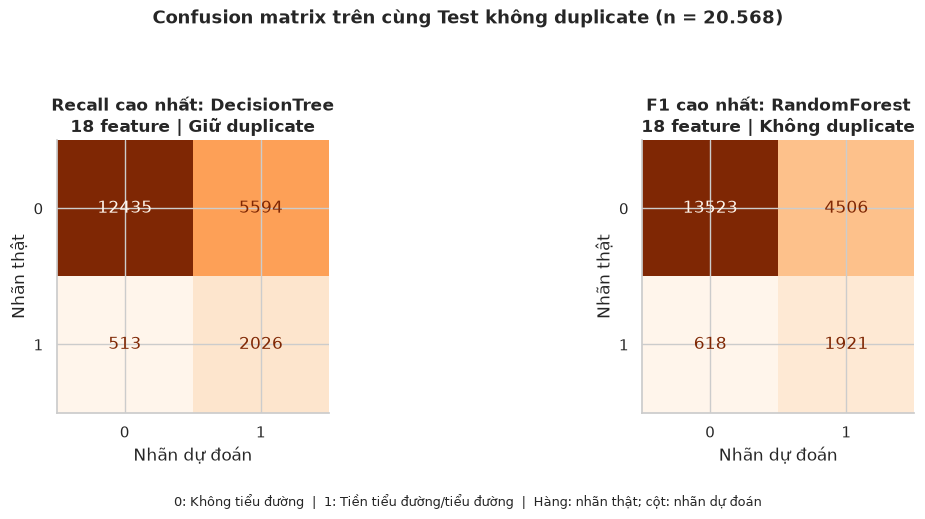

,Priority,Config,TestRows,TN,FP,FN,TP
0,Recall cao nhất,reduced_18__keep_duplicates__DecisionTree__bal...,20568,12435,5594,513,2026
1,F1 cao nhất,reduced_18__no_duplicates__RandomForest__balanced,20568,13523,4506,618,1921


**Recall cao nhất:** phát hiện đúng 2,026 hồ sơ lớp 1, bỏ sót 513; dự đoán nhầm dương 5,594 hồ sơ lớp 0. Đây là số đếm trên Test chung, không phải các ca bệnh được xác minh bằng xét nghiệm.

**F1 cao nhất:** phát hiện đúng 1,921 hồ sơ lớp 1, bỏ sót 618; dự đoán nhầm dương 4,506 hồ sơ lớp 0. Đây là số đếm trên Test chung, không phải các ca bệnh được xác minh bằng xét nghiệm.

In [18]:
METRIC_COLUMNS = 'Accuracy,Precision,Recall,"F1-score"'
for feature_set_name in FEATURE_SET_ORDER:
    for dataset in datasets:
        assert (
            scalar(
                'SELECT COUNT(*) FROM native_results WHERE "Feature set"=? AND Dataset=?',
                (feature_set_name, dataset),
            )
            == 4
        )
        display(Markdown(f"### {feature_set_name} / {dataset}: Test tương ứng"))
        display(
            table(
                f'SELECT Model,{METRIC_COLUMNS} FROM native_results WHERE "Feature set"=? AND Dataset=? ORDER BY Model',
                (feature_set_name, dataset),
            ).round(4)
        )
DB.execute(
    'CREATE VIEW ranked_results AS SELECT ROW_NUMBER() OVER(ORDER BY Recall DESC,"F1-score" DESC,Features,Config) AS Rank,* FROM common_results'
)
export_sql(
    "SELECT * FROM ranked_results ORDER BY Rank",
    RESULTS / "common_test_recall_ranking.csv",
)
display(Markdown("### 24 cấu hình có trọng số trên cùng Test đã loại duplicate"))
display(
    table(
        f"SELECT Rank,Dataset,Features,Model,{METRIC_COLUMNS} FROM ranked_results ORDER BY Rank"
    ).round(4)
)
note(
    "Nhóm dùng bảng để mô tả kết quả trên Test đã xem. Nhóm dành lựa chọn tham số và ngưỡng cho validation ở Ongoing 3."
)
recall_leader = records("SELECT * FROM ranked_results WHERE Rank=1")[0]
f1_leader = records(
    'SELECT * FROM common_results ORDER BY "F1-score" DESC,Precision DESC,Config LIMIT 1'
)[0]
display(Markdown("### Hai cách ưu tiên trên cùng Test"))
display(
    table(
        f"""SELECT 'Recall cao nhất' AS Priority,Dataset,Features,Model,{METRIC_COLUMNS} FROM ranked_results WHERE Rank=1 UNION ALL SELECT 'F1 cao nhất',Dataset,Features,Model,{METRIC_COLUMNS} FROM (SELECT * FROM common_results ORDER BY "F1-score" DESC,Precision DESC,Config LIMIT 1)"""
    ).round(4)
)
note(
    f"Cấu hình đứng đầu Recall có Precision {recall_leader['Precision']:.2%}; trong các dự đoán dương, {1-recall_leader['Precision']:.2%} mang nhãn thật 0. Cấu hình đứng đầu F1 đạt Recall {f1_leader['Recall']:.2%} và Precision {f1_leader['Precision']:.2%}. Nhóm chưa kết luận mô hình tốt nhất toàn diện; các chênh lệch nhỏ chưa có ước lượng độ bất định."
)


# Majority-class reference: determine the predicted class strictly from each Train.
# SQL counts give the same result as a most_frequent Dummy; no new ML model is fit.
DB.execute("""
    CREATE VIEW majority_train AS
    SELECT Dataset, label AS MajorityClass FROM (
        SELECT Dataset, Diabetes_binary AS label,
               ROW_NUMBER() OVER(PARTITION BY Dataset ORDER BY COUNT(*) DESC, Diabetes_binary) AS rank
        FROM dataset_rows JOIN clean_data USING(row_id)
        WHERE split='train' GROUP BY Dataset,Diabetes_binary
    ) WHERE rank=1
""")
assert scalar('SELECT COUNT(*) FROM majority_train WHERE MajorityClass!=0') == 0
DB.execute("""
    CREATE TABLE majority_baselines (
        Dataset TEXT,TestView TEXT,TestRows INTEGER,MajorityClass INTEGER,
        TN INTEGER,FP INTEGER,FN INTEGER,TP INTEGER,
        Accuracy REAL,Precision REAL,Recall REAL,"F1-score" REAL
    )
""")
for training_dataset in datasets:
    for view,evaluation_dataset in [('native',training_dataset),('common','no_duplicates')]:
        DB.execute("""
            INSERT INTO majority_baselines
            SELECT ?,?,n,majority,tn,fp,fn,tp,
                   1.0*(tp+tn)/n,
                   COALESCE(1.0*tp/NULLIF(tp+fp,0),0),
                   COALESCE(1.0*tp/NULLIF(tp+fn,0),0),
                   COALESCE(2.0*tp/NULLIF(2*tp+fp+fn,0),0)
            FROM (
                SELECT COUNT(*) AS n,m.MajorityClass AS majority,
                       SUM(d.Diabetes_binary=0 AND m.MajorityClass=0) AS tn,
                       SUM(d.Diabetes_binary=0 AND m.MajorityClass=1) AS fp,
                       SUM(d.Diabetes_binary=1 AND m.MajorityClass=0) AS fn,
                       SUM(d.Diabetes_binary=1 AND m.MajorityClass=1) AS tp
                FROM clean_data d JOIN dataset_rows r USING(row_id)
                JOIN majority_train m ON m.Dataset=?
                WHERE r.Dataset=? AND r.split='test'
            )
        """,(training_dataset,view,training_dataset,evaluation_dataset))
display(Markdown('### Mốc đối chiếu: luôn dự đoán lớp đông nhất của Train'))
display(table('SELECT Dataset,TestView,TestRows,MajorityClass,Accuracy,Precision,Recall,"F1-score" FROM majority_baselines ORDER BY TestView,Dataset').round(4))
export_sql('SELECT * FROM majority_baselines ORDER BY TestView,Dataset',RESULTS/'majority_baseline_metrics.csv')
note('Cả hai bản Train có lớp đông nhất là 0. Mốc này không dùng feature hoặc trọng số lớp để quyết định nhãn, không nằm trong 24 cấu hình và không nhân theo bộ feature. Trên cùng Test không duplicate, Accuracy đạt 87,66% nhưng Precision/Recall/F1 lớp 1 bằng 0. Vì không dự đoán lớp 1, Precision được quy ước 0.')

# Confusion matrices for the two reported priorities, always on common Test.
from sklearn.metrics import ConfusionMatrixDisplay
DB.execute('CREATE TABLE confusion_counts (Priority TEXT,Config TEXT,TestRows INTEGER,TN INTEGER,FP INTEGER,FN INTEGER,TP INTEGER)')
fig,axes=plt.subplots(1,2,figsize=(12,5.2))
for ax,(priority,leader) in zip(axes,[('Recall cao nhất',recall_leader),('F1 cao nhất',f1_leader)]):
    DB.execute("""
        INSERT INTO confusion_counts
        SELECT ?,?,COUNT(*),
               SUM(d.Diabetes_binary=0 AND p.predicted=0),
               SUM(d.Diabetes_binary=0 AND p.predicted=1),
               SUM(d.Diabetes_binary=1 AND p.predicted=0),
               SUM(d.Diabetes_binary=1 AND p.predicted=1)
        FROM predictions p JOIN clean_data d USING(row_id)
        JOIN dataset_rows r USING(row_id)
        WHERE p.Config=? AND r.Dataset='no_duplicates' AND r.split='test'
    """,(priority,leader['Config'],leader['Config']))
    count=records('SELECT * FROM confusion_counts WHERE Priority=?',(priority,))[0]
    cm=np.array([[count['TN'],count['FP']],[count['FN'],count['TP']]],dtype=np.int64)
    # Independently check both orientation and counts with scikit-learn.
    observed=records("""
        SELECT d.Diabetes_binary AS actual,p.predicted
        FROM predictions p JOIN clean_data d USING(row_id)
        JOIN dataset_rows r USING(row_id)
        WHERE p.Config=? AND r.Dataset='no_duplicates' AND r.split='test'
        ORDER BY d.row_id
    """,(leader['Config'],))
    checked=confusion_matrix([v['actual'] for v in observed],[v['predicted'] for v in observed],labels=[0,1])
    assert np.array_equal(cm,checked)
    assert int(cm.sum())==common_test_rows
    assert np.isclose(count['TP']/(count['TP']+count['FN']),leader['Recall'])
    assert np.isclose(count['TP']/(count['TP']+count['FP']),leader['Precision'])
    ConfusionMatrixDisplay(cm,display_labels=['0','1']).plot(ax=ax,cmap='Oranges',colorbar=False,values_format='d')
    dataset_label='Giữ duplicate' if leader['Dataset']=='keep_duplicates' else 'Không duplicate'
    ax.set_title(f"{priority}: {leader['Model']}\n{leader['Features']} feature | {dataset_label}")
    ax.set_xlabel('Nhãn dự đoán');ax.set_ylabel('Nhãn thật')
fig.suptitle('Confusion matrix trên cùng Test không duplicate (n = 20.568)',fontsize=13,fontweight='bold')
fig.text(.5,.025,'0: Không tiểu đường  |  1: Tiền tiểu đường/tiểu đường  |  Hàng: nhãn thật; cột: nhãn dự đoán',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.07,1,.92])
save_and_show_figure('model_confusion_matrices_common_test',fig)
display(table('SELECT * FROM confusion_counts'))
export_sql('SELECT * FROM confusion_counts',RESULTS/'confusion_counts_common_test.csv')
for row in records('SELECT * FROM confusion_counts'):
    note(f"**{row['Priority']}:** phát hiện đúng {row['TP']:,} hồ sơ lớp 1, bỏ sót {row['FN']:,}; dự đoán nhầm dương {row['FP']:,} hồ sơ lớp 0. Đây là số đếm trên Test chung, không phải các ca bệnh được xác minh bằng xét nghiệm.")


In [19]:
# Reload exported predictions without pandas and verify SQL metrics with sklearn.
with (RESULTS / "all_test_predictions.csv").open(
    encoding="utf-8-sig", newline=""
) as stream:
    reader = csv.reader(stream)
    headers = next(reader)
    DB.execute(
        "CREATE TABLE exported_predictions ("
        + ", ".join(ident(c) + " INTEGER" for c in headers)
        + ")"
    )
    DB.executemany(
        "INSERT INTO exported_predictions VALUES ("
        + ",".join("?" for _ in headers)
        + ")",
        reader,
    )
for result in records(
    'SELECT c.*,m.TestView,m.Accuracy,m.Precision,m.Recall,m."F1-score",m.TestRows FROM configurations c JOIN metric_results m USING(Config) ORDER BY c.Config,m.TestView'
):
    dataset = result["Dataset"] if result["TestView"] == "native" else "no_duplicates"
    actual = records(
        f"SELECT e.Actual,e.{ident(result['Config'])} AS predicted FROM exported_predictions e JOIN dataset_rows r USING(row_id) WHERE r.Dataset=? AND r.split='test' ORDER BY e.row_id",
        (dataset,),
    )
    labels = np.array([r["Actual"] for r in actual])
    predicted = np.array([r["predicted"] for r in actual])
    independently_checked = {
        "Accuracy": accuracy_score(labels, predicted),
        "Precision": precision_score(labels, predicted, zero_division=0),
        "Recall": recall_score(labels, predicted, zero_division=0),
        "F1-score": f1_score(labels, predicted, zero_division=0),
    }
    for metric, value in independently_checked.items():
        assert np.isclose(result[metric], value, atol=1e-14)
    weights = training_class_weights(result["Dataset"])
    for key, value in weights.items():
        assert np.isclose(result[key], value)
    verify_weighting_parameters(run_parameters[result["Config"]], weights)
assert scalar("SELECT COUNT(*) FROM exported_predictions") == 23333
assert (
    scalar(
        "SELECT COUNT(*) FROM (SELECT group_id FROM split_manifest GROUP BY group_id HAVING COUNT(DISTINCT split)>1)"
    )
    == 0
)
assert scalar(f"SELECT COUNT(*) FROM clean_dedup") == scalar(
    f"SELECT COUNT(*) FROM (SELECT DISTINCT {ALL_COLUMNS} FROM clean_dedup)"
)
metadata = {
    "status": "passed",
    "fits": EXPECTED_CONFIGS,
    "fits_by_weighting": {"balanced": 24},
    "feature_counts": [18, 16, 21],
    "deduplication_key": [TARGET] + FEATURES,
    "deduplication_before_feature_reduction": True,
    "deduplication_keep": "first by MIN(row_id)",
    "deduplication_method": "SELECT into view; source retained",
    "group_split_key": FEATURES,
    "model_input_dtype": "int16",
    "data_operations": "SQLite",
    "dataset_sizes": records(
        "SELECT * FROM dataset_split_summary ORDER BY Dataset,Split DESC"
    ),
    "common_test_rows": common_test_rows,
    "metrics_source": "SQL confusion counts",
    "four_metrics_recomputed_from_saved_predictions": True,
    "verification_library": "scikit-learn",
    "cv_used": False,
    "oof_used": False,
    "weighting_used": True,
    "weighting_modes": ["balanced"],
    "weights_source": "training labels for each dataset only",
    "resampling_used": False,
    "threshold_search_used": False,
    "model_parameters": run_parameters,
    "highest_recall_configuration": recall_leader["Config"],
    "limitation": "Exploratory comparison on previously viewed Test; not an independent final assessment.",
}
(RESULTS / "validation_and_design.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
)
print("Đã kiểm tra đủ 24 cấu hình và bốn chỉ số từ file dự đoán bằng scikit-learn.")


Đã kiểm tra đủ 24 cấu hình và bốn chỉ số từ file dự đoán bằng scikit-learn.


# PART 4: DISCUSSION, CONCLUSION & RECOMMENDATIONS [1.0 POINT]

Nhóm đánh giá 24 cấu hình dùng trọng số từ sáu trường hợp dữ liệu/feature. Decision Tree với 18 feature và Train giữ duplicate đạt Recall cao nhất 79,80%; Precision 26,59% và F1 39,89%. Random Forest với 18 feature và Train loại duplicate đạt Precision 29,89% và F1 42,85%, cao nhất trong 24 cấu hình. Nhóm tính các số này trên cùng 20.568 hồ sơ Test đã loại duplicate.

Nhóm dùng thứ hạng để mô tả kết quả, chưa kết luận cấu hình đứng đầu tối ưu. Nhóm không xếp hạng trực tiếp chỉ số trên hai Test tương ứng có phân bố khác nhau.

Giữ duplicate có thể làm tăng trọng số ngầm cho các hồ sơ phổ biến; loại duplicate cũng không bảo đảm các dòng đó thuộc cùng một người vì không có định danh cá nhân. Đối chiếu hai cách là phân tích độ nhạy, không khẳng định một cách đúng cho mọi trường hợp. Test chung là bản đã loại duplicate theo 22 cột, chưa đại diện quần thể và chưa có trọng số khảo sát.

Recall được ưu tiên theo mục tiêu nghiên cứu, nhưng cần đọc kèm Precision và F1. Không diễn giải dự đoán nhãn khảo sát thành chẩn đoán hay dự đoán phát bệnh tương lai. Nhãn gộp tiền tiểu đường/tiểu đường tự khai, giới hạn ở tuổi 30-59 sau làm sạch.

Test đã được xem trong các lần phát triển và dùng cho đối chiếu/lựa chọn sơ bộ này. Điểm đứng đầu không phải đánh giá cuối độc lập và chưa cho biết độ ổn định. Ongoing 3 cần thiết kế chọn mô hình bằng Train/Validation trước khi tuning hay xác nhận lựa chọn; không tiếp tục tối ưu rồi coi Test hiện tại là đánh giá chưa từng sử dụng.

Nguồn: dữ liệu sạch Ongoing 1, manifest và tham số cố định Ongoing 2 của nhóm; [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html).

**Diễn giải và khuyến nghị trong phạm vi học tập:** Với cấu hình Recall cao nhất, nhóm thu được Precision 26,59%; khoảng 73,41% dự đoán dương mang nhãn thật 0. Nhóm cần cân nhắc khối lượng kiểm tra thêm nếu thử dùng mô hình để sàng lọc trong một nghiên cứu tiếp theo. Các tỷ lệ này mô tả nhãn khảo sát của mẫu, chưa đủ làm căn cứ triển khai chẩn đoán. Nhóm chưa kết luận trọng số cải thiện hiệu năng vì báo cáo không có đối chiếu chưa trọng số.

Nhóm quan sát liên hệ giữa nhãn và GenHlth, huyết áp, BMI cùng tuổi; nhóm đề xuất kiểm tra các liên hệ này sau khi điều chỉnh các biến khác trong nghiên cứu tiếp theo. Nhóm không suy ra can thiệp sức khỏe từ các chênh lệch mô tả, gồm chênh lệch theo thu nhập và rượu.

**Việc cần làm ở Ongoing 3:**

1. Dùng các fold theo nhóm trong Train để chọn bộ biến và tham số; fit preprocessing và tính trọng số riêng trong từng fold.
2. Xác định mục tiêu Precision/Recall với giảng viên trước khi chọn cấu hình. Nếu nhóm chọn ràng buộc Recall, nhóm chỉ chọn ngưỡng bằng validation và báo cáo Precision/F1 đi kèm.
3. Ước lượng độ biến động giữa các fold, kiểm tra sai số theo nhóm tuổi và giới, rồi khóa cấu hình trước bước xác nhận.
4. Giữ Test hiện tại làm kết quả đối chiếu đã xem. Nếu cần tuyên bố khả năng khái quát độc lập, nhóm cần một tập xác nhận chưa tham gia phát triển và kiểm tra sự tương thích của dữ liệu.


**Đối chiếu tối thiểu và sai số:** Mốc luôn dự đoán lớp đông nhất được xác định từ Train, đạt Accuracy 87,66% trên Test chung nhưng Recall/F1 lớp 1 bằng 0. Hai confusion matrix ở Phần 3 cho biết cụ thể TP/TN/FP/FN của hai cấu hình được nhấn mạnh, giúp đọc Recall cùng số bỏ sót và số dự đoán nhầm dương. Chúng không làm thay đổi cách huấn luyện hoặc lựa chọn ngưỡng.


# PHỤ LỤC A: BẢNG CHI TIẾT VÀ PHÂN BỐ ĐẶC TRƯNG

Phụ lục chỉ dùng Train từ Phần 1. Các hình và bảng này không thay đổi dữ liệu mô hình.

## A.1. Phân bố biến nhị phân và thứ bậc

BMI, MentHlth và PhysHlth đã có histogram tại mục 1.1.b; hai khung dưới bổ sung
18 đặc trưng còn lại. Income tính bằng nghìn USD/hộ/năm.


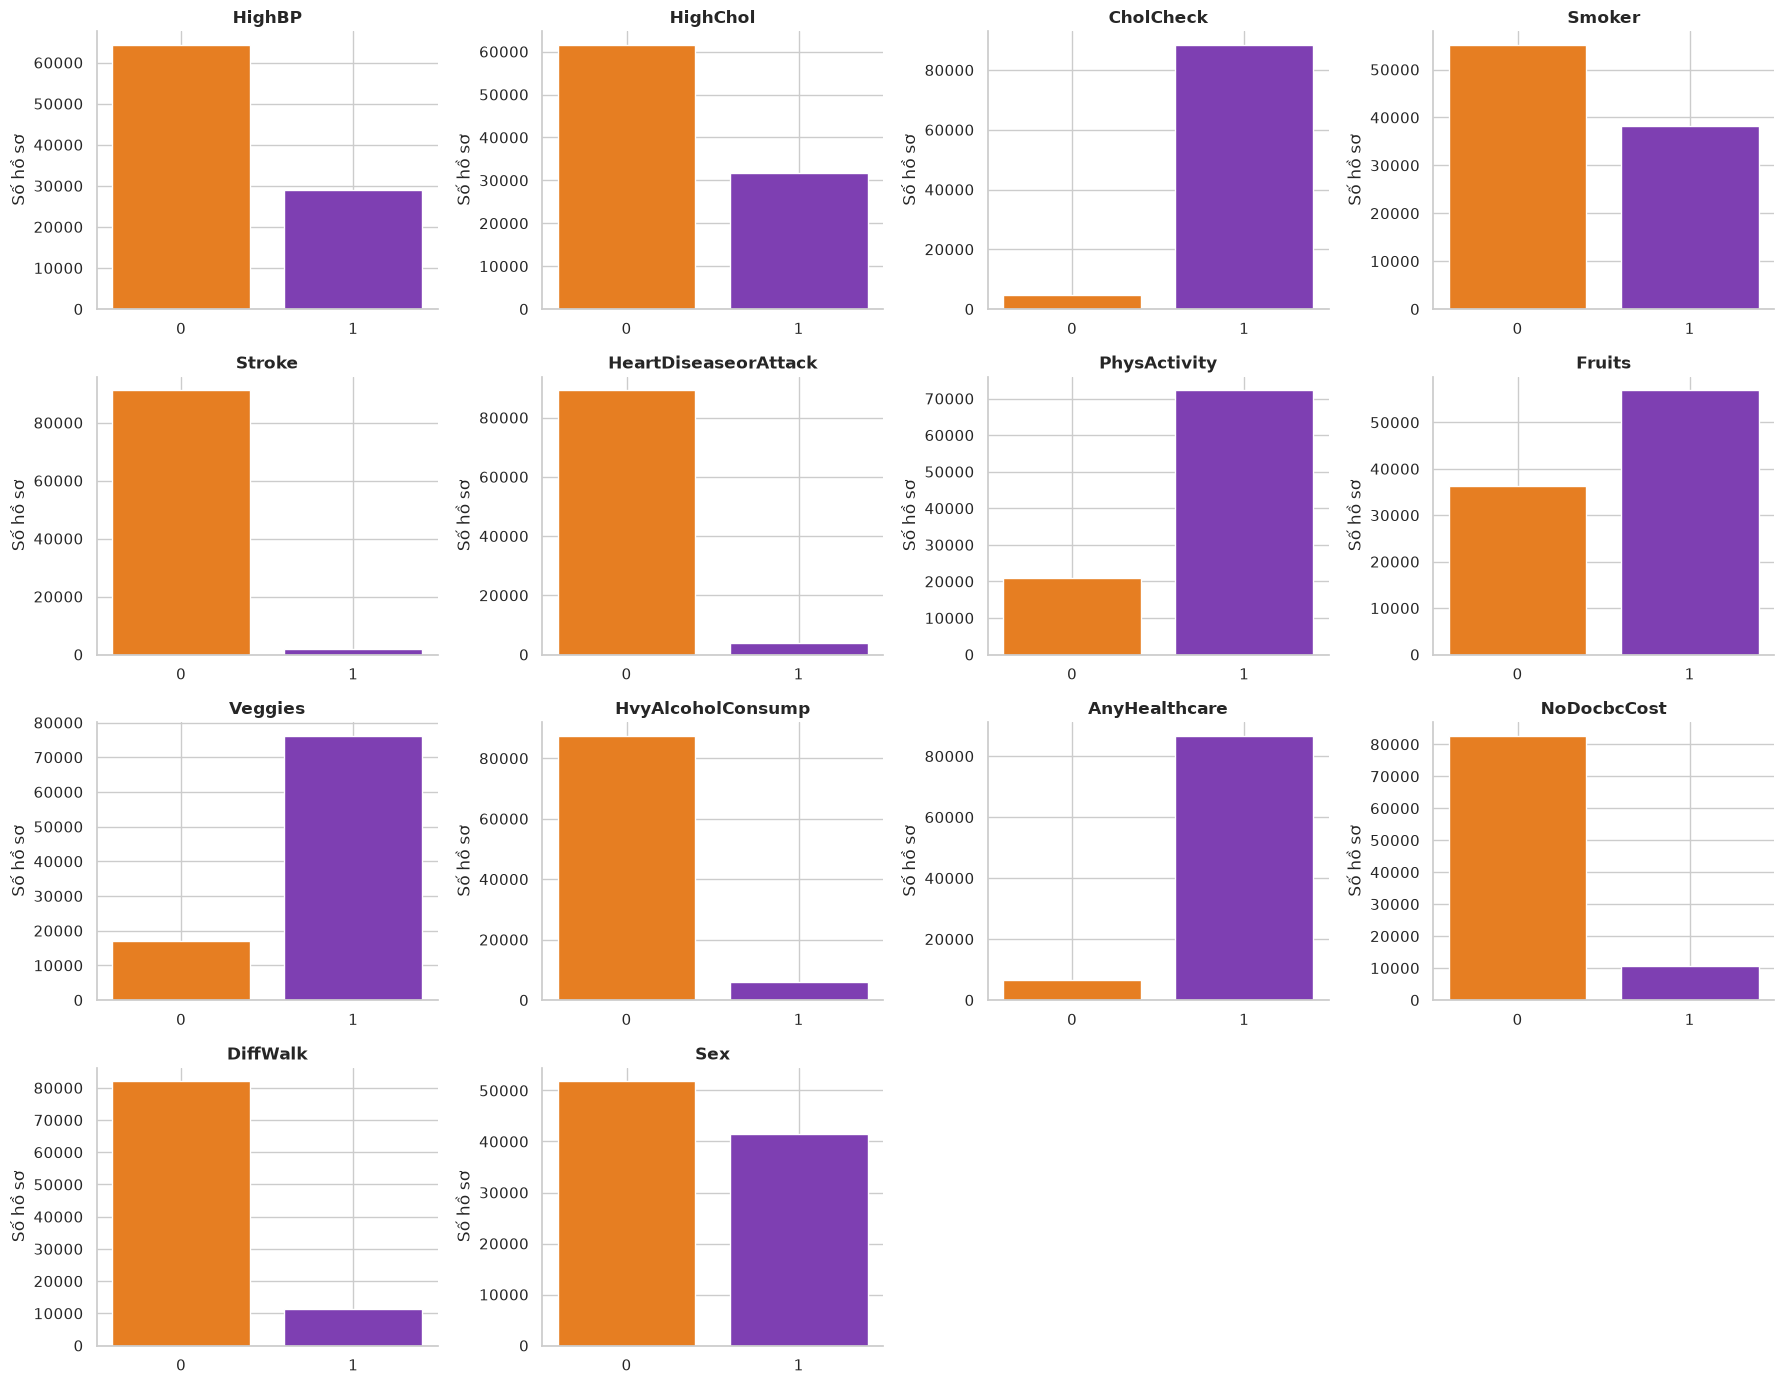

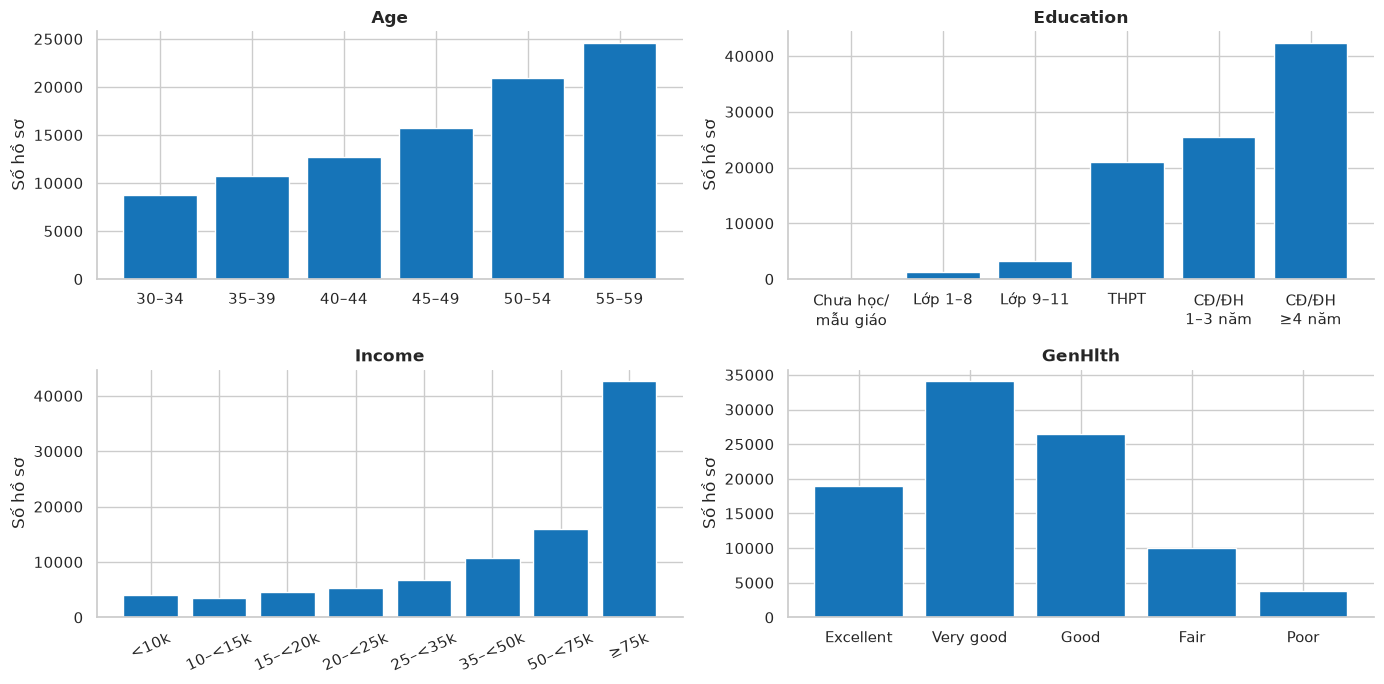

In [20]:
fig = plot_category_counts(BINARY, LABEL_MAPS, columns=4)
save_and_show_figure("appendix_01_binary_counts", fig)
fig = plot_category_counts(list(ORDINAL_DOMAINS), LABEL_MAPS, columns=2)
save_and_show_figure("appendix_02_ordinal_counts", fig)


## A.2. Số mẫu và tỷ lệ lớp 1 trong từng mức

`sample_count`: số hồ sơ; `positive_count`: số hồ sơ lớp 1;
`positive_rate`: phần trăm lớp 1 trong mức đó. Tỷ lệ trống tương ứng n=0.


In [21]:
for feature in EDA_LEVELS:
    sql = f"SELECT level AS {ident(feature)},sample_count,positive_count,positive_rate FROM feature_summary WHERE Feature=? ORDER BY position"
    display(Markdown(f"**{feature}**"))
    display(table(sql, (feature,)).round(2))
    save_table(sql, "eda_groups_" + feature, (feature,))


**HighBP**

,HighBP,sample_count,positive_count,positive_rate
0,0,64398,3509,5.45
1,1,28931,6683,23.10


**HighChol**

,HighChol,sample_count,positive_count,positive_rate
0,0,61646,3699,6.00
1,1,31683,6493,20.49


**CholCheck**

...

,GenHlth,sample_count,positive_count,positive_rate
0,1,18916,301,1.59
1,2,34051,1663,4.88
2,3,26518,3781,14.26
3,4,9990,2966,29.69
4,5,3854,1481,38.43


**MentHlth**

,MentHlth,sample_count,positive_count,positive_rate
0,0,59478,5467,9.19
1,1,3784,292,7.72
2,2,5554,517,9.31
3,3,3233,331,10.24
4,4,1540,165,10.71
5,5,3919,432,11.02
6,6,389,48,12.34
7,7,1353,159,11.75
8,8,266,41,15.41
9,9,41,10,24.39


**PhysHlth**

,PhysHlth,sample_count,positive_count,positive_rate
0,0,59096,4368,7.39
1,1,5085,425,8.36
2,2,5998,664,11.07
3,3,3190,431,13.51
4,4,1676,227,13.54
5,5,2689,359,13.35
6,6,416,79,18.99
7,7,1632,226,13.85
8,8,299,57,19.06
9,9,60,14,23.33


## A.3. Pearson, Spearman và các cặp đặc trưng nổi bật


In [22]:
display(
    table(
        "SELECT Feature,Pearson,Spearman FROM correlation_target ORDER BY Pearson DESC,position"
    ).round(4)
)
display(
    table(
        'SELECT "Feature A","Feature B",Pearson FROM correlation_pairs ORDER BY ABS(Pearson) DESC,position_a,position_b LIMIT 5'
    ).round(4)
)
DB.commit()


,Feature,Pearson,Spearman
0,GenHlth,0.3123,0.2971
1,HighBP,0.2617,0.2617
2,BMI,0.2348,0.2341
3,DiffWalk,0.2221,0.2221
4,HighChol,0.2200,0.2200
5,PhysHlth,0.1977,0.1780
6,HeartDiseaseorAttack,0.1606,0.1606
7,Age,0.1345,0.1336
8,MentHlth,0.1247,0.0961
9,Stroke,0.1057,0.1057


,Feature A,Feature B,Pearson
0,PhysHlth,DiffWalk,0.5323
1,GenHlth,PhysHlth,0.5292
2,GenHlth,DiffWalk,0.4603
3,Education,Income,0.4341
4,GenHlth,Income,-0.4116
